N= 10  V0_kac=    0.00  trace=10.307 (should be 10)  lambda_0..3/N = [1.     0.0071 0.0067 0.0067]
N= 10  V0_kac=  -10.00  trace=9.912 (should be 10)  lambda_0..3/N = [0.9983 0.0072 0.0072 0.0066]
N= 10  V0_kac=  -20.00  trace=9.879 (should be 10)  lambda_0..3/N = [0.9909 0.0097 0.0069 0.0065]
N= 10  V0_kac=  -30.00  trace=9.875 (should be 10)  lambda_0..3/N = [0.9711 0.0282 0.0067 0.0067]
N= 10  V0_kac=  -40.00  trace=10.080 (should be 10)  lambda_0..3/N = [0.931  0.0691 0.0069 0.0069]
N= 10  V0_kac=  -50.00  trace=9.945 (should be 10)  lambda_0..3/N = [0.8577 0.1386 0.0068 0.0068]
N= 10  V0_kac=  -60.00  trace=9.765 (should be 10)  lambda_0..3/N = [0.7607 0.2346 0.0072 0.0072]
N= 10  V0_kac=  -70.00  trace=10.113 (should be 10)  lambda_0..3/N = [0.6752 0.3211 0.0091 0.0074]
N= 10  V0_kac=  -80.00  trace=10.094 (should be 10)  lambda_0..3/N = [0.6136 0.3817 0.0075 0.0075]
N= 10  V0_kac=  -90.00  trace=9.859 (should be 10)  lambda_0..3/N = [0.5748 0.4204 0.0072 0.0072]
N= 10  V0_kac= -

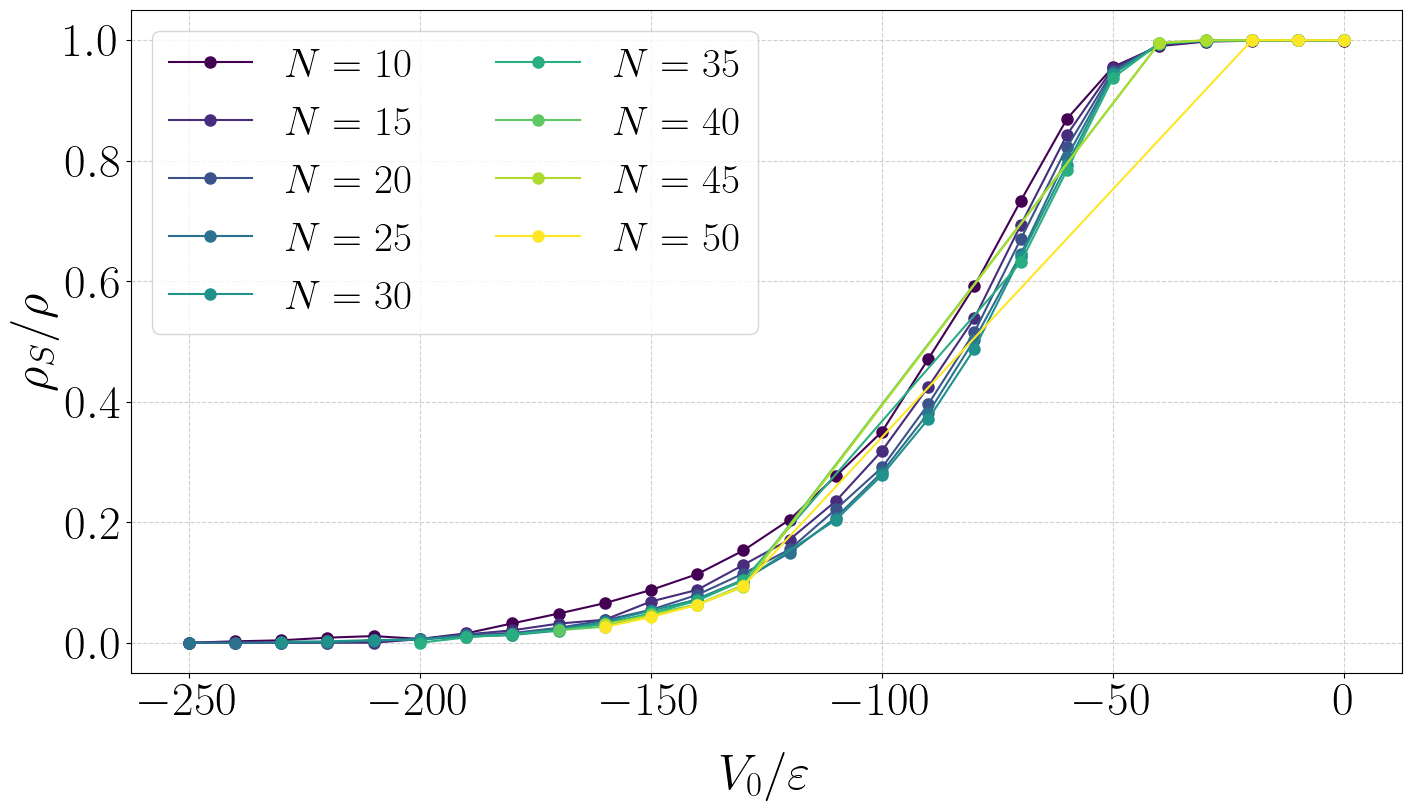

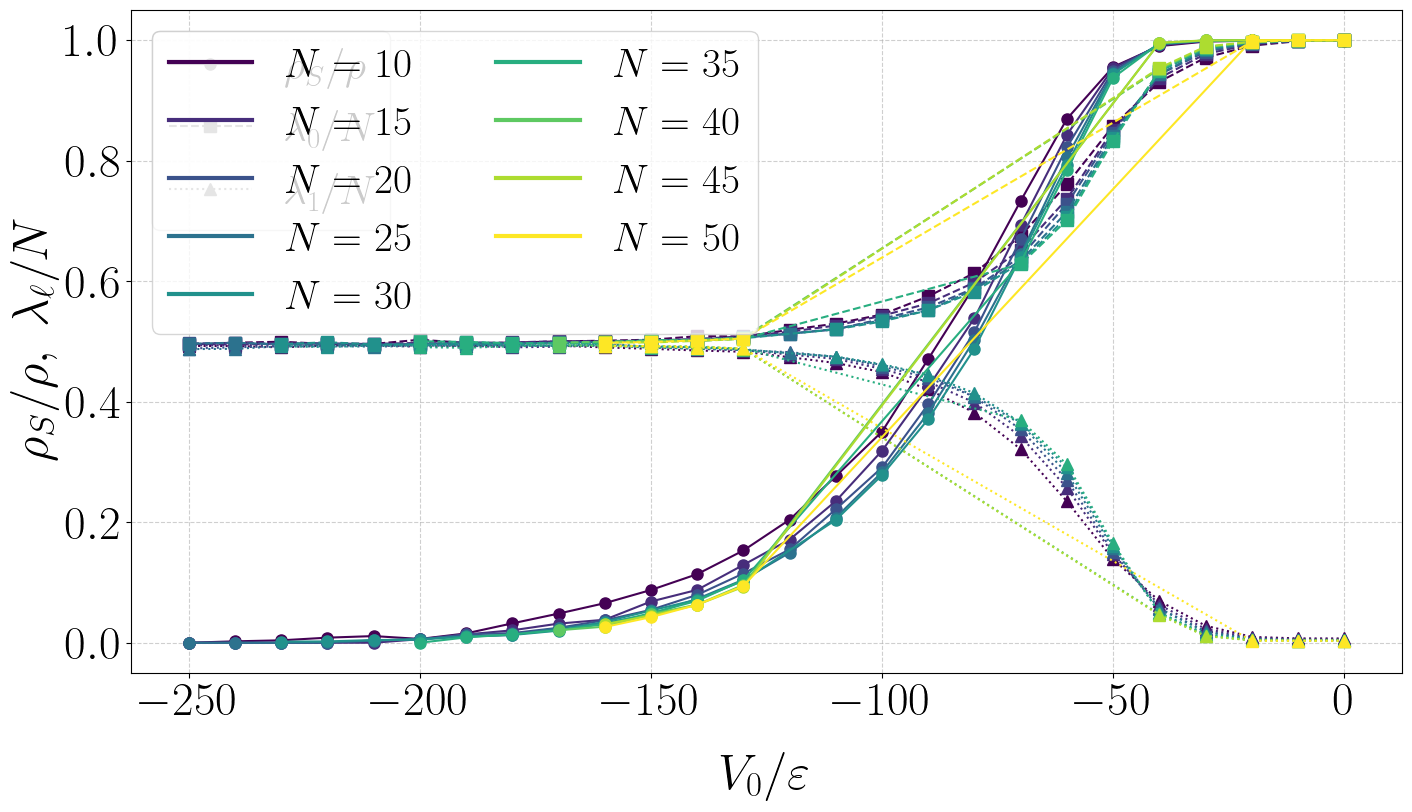

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import os

plt.rcParams.update({
    "pgf.texsystem": "pdflatex",
    "font.family": "serif",
    "font.size": 36,
    "axes.titlesize": 36,
    "axes.labelsize": 36,
    "xtick.labelsize": 34,
    "ytick.labelsize": 34,
    "legend.fontsize": 30,
    "figure.titlesize": 36,
    "text.usetex": True,
    "pgf.rcfonts": False,
})

# ------------------- DATA LOCATION -------------------

base = r"C:\Users\marta\Downloads\Cavity_mediated_interaction_TFM_restructured(2)\numpy_arrays_VMC\constant_density_1.0"
hist_1d_dir = os.path.join(base, "hist_1D")
obdm_dir    = os.path.join(base, "obdm")

density = 1.0                                  # rho; L = N / density
Ns_list = [10, 15, 20, 25, 30, 35, 40, 45, 50]
V0_kac_list = np.arange(0.0, -251.0, -10.0)    # Kac couplings V0_kac = N * V0 (bare)

# Interval over which hist_1D was binned in metropolis():
#   compute_zoom = true  -> one cavity period [-0.5, 0.5)   (interval = 1.0)
#   compute_zoom = false -> full box [-L/2, L/2)            (interval = L)
compute_zoom = True


def get_L(num_part):
    return num_part / density


def leggett_bound(num_part, V0_kac):
    """rho_S/rho upper bound (Leggett): 1 / (<n> <1/n>), averages over the binned interval."""
    L = get_L(num_part)
    V0 = V0_kac / num_part + 0.0               # bare V0 used in the simulation (+0.0 avoids "-0.000000")
    path = os.path.join(hist_1d_dir, f"V0={V0:.3f}",
                        f"hist_1D_{num_part}_{V0:.3f}_{L:.1f}.npy")
    if not os.path.isfile(path):
        raise FileNotFoundError(path)

    n_x = np.load(path).astype(float)
    interval = 1.0 if compute_zoom else L
    dx = interval / len(n_x)

    n_x /= np.sum(n_x * dx)                    # unit integral over the interval
    n_x = np.maximum(n_x, 1e-8)

    mean_n = np.sum(n_x * dx) / interval
    mean_inv_n = np.sum(dx / n_x) / interval
    return 1.0 / (mean_n * mean_inv_n)


def obdm_eigenvalues(num_part, V0_kac):
    """Eigenvalues of the one-body density matrix, sorted descending, divided by N.

    rho_1(x, x') is saved on [-L/2, L/2)^2 with nb bins per side, normalized so that
    the trace of rho_1 * dx equals N. It is averaged over lattice translations
    (x, x') -> (x + n, x' + n) before diagonalizing, which is exact and reduces noise.
    """
    L = get_L(num_part)
    V0 = V0_kac / num_part + 0.0
    path = os.path.join(obdm_dir, f"V0={V0:.3f}",
                        f"obdm_{num_part}_{V0:.3f}_{L:.1f}.npy")
    if not os.path.isfile(path):
        raise FileNotFoundError(path)

    rho1 = np.load(path).astype(float)
    nb = rho1.shape[0]
    dx = L / nb

    n_cells = int(round(L))                    # number of cavity periods in the box
    if nb % n_cells == 0:
        shift = nb // n_cells
        rho1 = sum(np.roll(rho1, (n * shift, n * shift), axis=(0, 1))
                   for n in range(n_cells)) / n_cells

    lam = np.linalg.eigvalsh(rho1 * dx)[::-1]
    return lam / num_part, lam.sum()


# ------------------- COMPUTE rho_S/rho -------------------

results = {}
for num_part in Ns_list:
    V0_valid, rho_s = [], []
    for V0_kac in V0_kac_list:
        try:
            rho_s.append(leggett_bound(num_part, V0_kac))
            V0_valid.append(V0_kac)
        except FileNotFoundError:
            continue
    if rho_s:
        results[num_part] = (np.array(V0_valid), np.array(rho_s))
    else:
        print(f"No data found for N={num_part}")

# ------------------- COMPUTE OBDM EIGENVALUES -------------------

obdm_results = {}
for num_part in Ns_list:
    V0_valid, lam0, lam1 = [], [], []
    for V0_kac in V0_kac_list:
        try:
            lam, trace = obdm_eigenvalues(num_part, V0_kac)
        except FileNotFoundError:
            continue
        V0_valid.append(V0_kac)
        lam0.append(lam[0])
        lam1.append(lam[1])
        print(f"N={num_part:3d}  V0_kac={V0_kac:8.2f}  trace={trace:.3f} (should be {num_part})  "
              f"lambda_0..3/N = {np.round(lam[:4], 4)}")
    if V0_valid:
        obdm_results[num_part] = (np.array(V0_valid), np.array(lam0), np.array(lam1))
    else:
        print(f"No OBDM data found for N={num_part}")

print("\nN, V0_kac, rho_S/rho")
for num_part, (V0_valid, rho_s) in results.items():
    for V0, r in zip(V0_valid, rho_s):
        print(f"{num_part:3d}  {V0:8.2f}  {r:.5f}")

# ------------------- PLOT: all N on one axes -------------------

Ns_with_data = sorted(results.keys())
fig, ax = plt.subplots(figsize=(15, 9))
colors = plt.cm.viridis(np.linspace(0, 1, max(len(Ns_with_data), 2)))

for color, num_part in zip(colors, Ns_with_data):
    V0_valid, rho_s = results[num_part]
    ax.plot(V0_valid, rho_s, "-o", color=color, markersize=8, linewidth=1.5,
            label=fr"$N={num_part}$")

ax.set_xlabel(r"$V_0/\varepsilon$", labelpad=20)
ax.set_ylabel(r"$\rho_S/\rho$")
ax.set_ylim(-0.05, 1.05)
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(ncol=2)
plt.tight_layout()

os.makedirs("final_imag", exist_ok=True)
plt.savefig("final_imag/rhos_vs_V0_leggett.pdf", dpi=600, bbox_inches="tight")

# ------------------- PLOT: rho_S/rho together with the OBDM eigenvalues -------------------
#   solid  + circles   : rho_S/rho (Leggett bound)
#   dashed + squares   : lambda_0 / N  (largest OBDM eigenvalue)
#   dotted + triangles : lambda_1 / N  (second eigenvalue; -> 1/2 signals Z2 fragmentation)

from matplotlib.lines import Line2D

Ns_all = sorted(set(results) | set(obdm_results))
fig2, ax2 = plt.subplots(figsize=(15, 9))
colors2 = plt.cm.viridis(np.linspace(0, 1, max(len(Ns_all), 2)))

for color, num_part in zip(colors2, Ns_all):
    if num_part in results:
        V0_valid, rho_s = results[num_part]
        ax2.plot(V0_valid, rho_s, "-o", color=color, markersize=8, linewidth=1.5)
    if num_part in obdm_results:
        V0_valid, lam0, lam1 = obdm_results[num_part]
        ax2.plot(V0_valid, lam0, "--s", color=color, markersize=8, linewidth=1.5)
        ax2.plot(V0_valid, lam1, ":^", color=color, markersize=8, linewidth=1.5)

style_handles = [
    Line2D([0], [0], color="gray", linestyle="-",  marker="o", markersize=8, label=r"$\rho_S/\rho$"),
    Line2D([0], [0], color="gray", linestyle="--", marker="s", markersize=8, label=r"$\lambda_0/N$"),
    Line2D([0], [0], color="gray", linestyle=":",  marker="^", markersize=8, label=r"$\lambda_1/N$"),
]
N_handles = [Line2D([0], [0], color=c, linewidth=3, label=fr"$N={n}$")
             for c, n in zip(colors2, Ns_all)]
leg1 = ax2.legend(handles=style_handles, loc="upper left")
ax2.add_artist(leg1)
if len(Ns_all) > 1:
    ax2.legend(handles=N_handles, loc="upper left", ncol=2)

ax2.set_xlabel(r"$V_0/\varepsilon$", labelpad=20)
ax2.set_ylabel(r"$\rho_S/\rho,\ \lambda_\ell/N$")
ax2.set_ylim(-0.05, 1.05)
ax2.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("final_imag/rhos_and_obdm_vs_V0.pdf", dpi=600, bbox_inches="tight")
plt.show()

N= 10  V0_kac=    0.00  trace=10.307 (should be 10)  lambda_0..3/N = [1.     0.0071 0.0067 0.0067]
N= 10  V0_kac=  -30.00  trace=9.875 (should be 10)  lambda_0..3/N = [0.9711 0.0282 0.0067 0.0067]
N= 10  V0_kac=  -60.00  trace=9.765 (should be 10)  lambda_0..3/N = [0.7607 0.2346 0.0072 0.0072]
N= 10  V0_kac=  -90.00  trace=9.859 (should be 10)  lambda_0..3/N = [0.5748 0.4204 0.0072 0.0072]
N= 10  V0_kac= -120.00  trace=10.005 (should be 10)  lambda_0..3/N = [0.5192 0.4738 0.0089 0.0084]
N= 10  V0_kac= -150.00  trace=9.802 (should be 10)  lambda_0..3/N = [0.5028 0.4877 0.007  0.007 ]
N= 10  V0_kac= -180.00  trace=9.809 (should be 10)  lambda_0..3/N = [0.498  0.493  0.0069 0.0069]

N, V0_kac, rho_S/rho
 10      0.00  0.99936
 10    -30.00  0.99760
 10    -60.00  0.86933
 10    -90.00  0.47092
 10   -120.00  0.20421
 10   -150.00  0.08756
 10   -180.00  0.03215
missing: C:\Users\marta\Downloads\Cavity_mediated_interaction_TFM_restructured(2)\numpy_arrays_VMC\constant_density_1.0\SSF\V0=0.

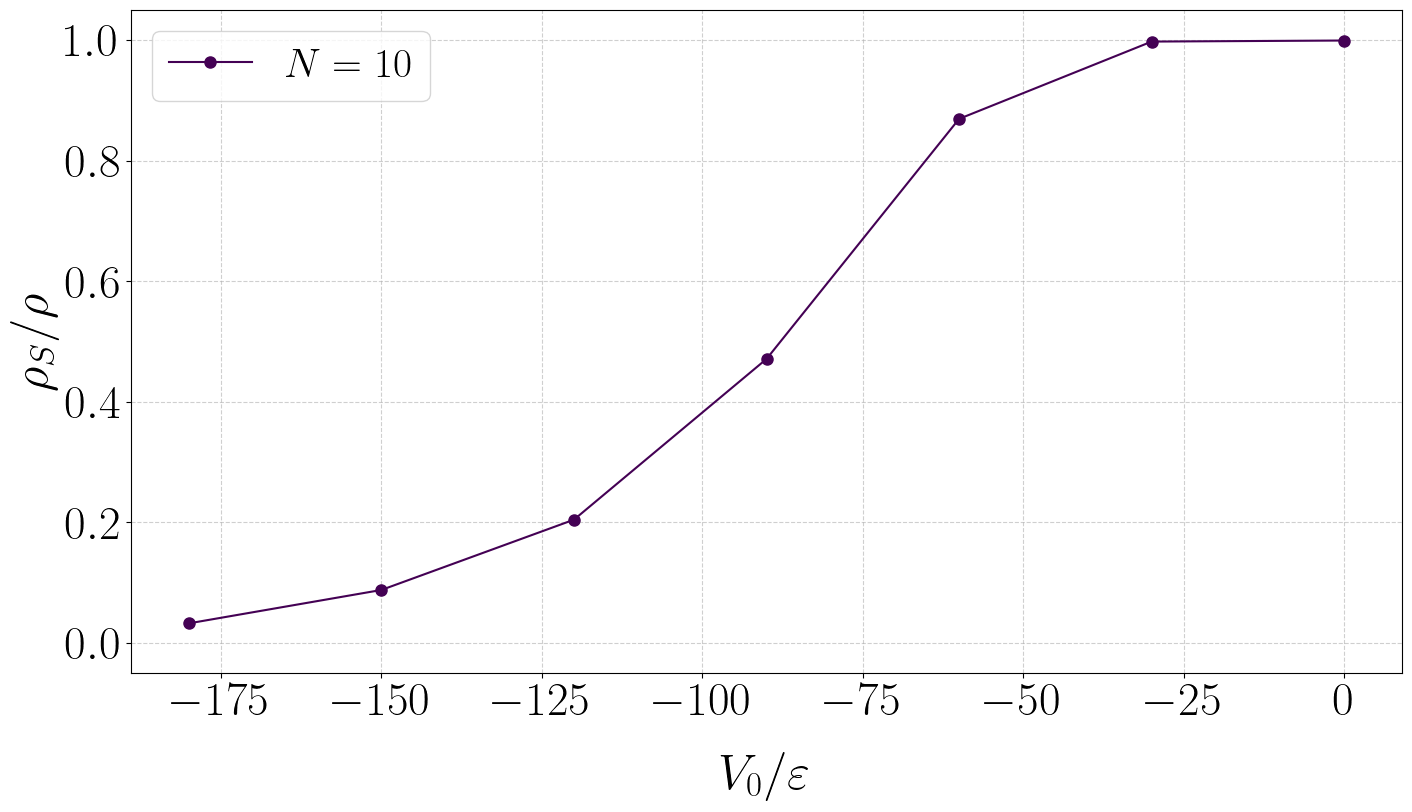

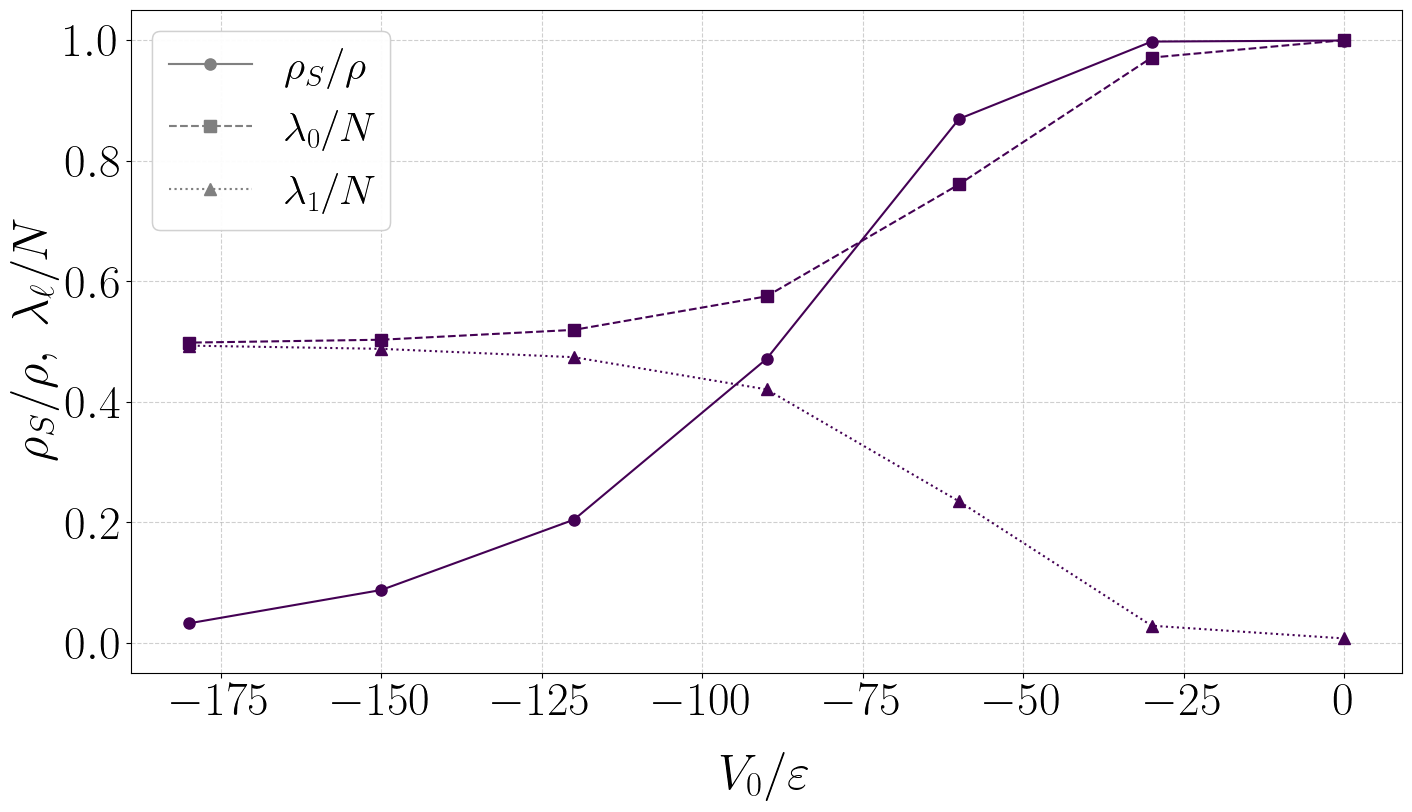

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import os

plt.rcParams.update({
    "pgf.texsystem": "pdflatex",
    "font.family": "serif",
    "font.size": 36,
    "axes.titlesize": 36,
    "axes.labelsize": 36,
    "xtick.labelsize": 34,
    "ytick.labelsize": 34,
    "legend.fontsize": 30,
    "figure.titlesize": 36,
    "text.usetex": True,
    "pgf.rcfonts": False,
})

# ------------------- DATA LOCATION -------------------

root = r"C:\Users\marta\Downloads\Cavity_mediated_interaction_TFM_restructured(2)"
base_vmc = os.path.join(root, "numpy_arrays_VMC", "constant_density_1.0")
base_dmc = os.path.join(root, "numpy_arrays_DMC", "constant_density_1.0")

# Which estimator to plot:
#   "vmc"          -> VMC data (observables of the trial wavefunction)
#   "dmc"          -> DMC mixed estimator
#   "extrapolated" -> 2 * DMC - VMC (first-order correction of the mixed-estimator bias)
estimator = "vmc"

# DMC run parameters (part of the DMC file names)
n_walkers = 200
dtau = 0.0010
n_steps = 3000
dmc_suffix = "IS"                              # importance sampling

density = 1.0                                  # rho; L = N / density
Ns_list = [10]
V0_kac_list = np.arange(0.0, -201.0, -30.0)    # Kac couplings V0_kac = N * V0 (bare)

# Interval over which hist_1D was binned in metropolis():
#   compute_zoom = true  -> one cavity period [-0.5, 0.5)   (interval = 1.0)
#   compute_zoom = false -> full box [-L/2, L/2)            (interval = L)
compute_zoom = True


def get_L(num_part):
    return num_part / density


def load_array(kind, num_part, V0_kac):
    """Load hist_1D, obdm or SSF for (N, V0_kac) with the chosen estimator.

    VMC folder : <kind>/V0=<V0>/<kind>_<N>_<V0>_<L>.npy
    DMC folder : <dir>/V0=<V0>/<pre>[_extrap]_<n_walkers>_<dtau>_<N>_<n_steps>_<V0>_<L>_<suffix>.npy
                 (hist_1D is stored as hist_1d/ with prefix hist1d; "_extrap" = 2*DMC - VMC
                 computed by the DMC run itself, "_vmc_" = the VMC of that same run).
    """
    L = get_L(num_part)
    V0 = V0_kac / num_part + 0.0               # bare V0 used in the simulation (+0.0 avoids "-0.000000")
    tail = f"{V0:.3f}_{L:.1f}"

    def _vmc_path():
        return os.path.join(base_vmc, kind, f"V0={V0:.3f}", f"{kind}_{num_part}_{tail}.npy")

    def _dmc_path(tag):                        # tag: "" (mixed estimator), "_extrap" or "_vmc"
        folder = "hist_1d" if kind == "hist_1D" else kind
        prefix = "hist1d" if kind == "hist_1D" else kind
        if tag == "_vmc":                      # VMC of the same DMC run (no DMC parameters in the name)
            name = f"{prefix}_vmc_{num_part}_{tail}.npy"
        else:
            name = f"{prefix}{tag}_{n_walkers}_{dtau:.4f}_{num_part}_{n_steps}_{tail}_{dmc_suffix}.npy"
        return os.path.join(base_dmc, folder, f"V0={V0:.3f}", name)

    def _load(path):
        if not os.path.isfile(path):
            raise FileNotFoundError(path)
        arr = np.load(path).real.astype(float)
        if kind == "hist_1D":                  # normalize n(x)
            interval = 1.0 if compute_zoom else L
            arr /= np.sum(arr) * interval / len(arr)
        return arr

    if estimator == "vmc":
        return _load(_vmc_path())
    if estimator == "dmc":
        return _load(_dmc_path(""))
    if estimator == "extrapolated":
        return _load(_dmc_path("_extrap"))
    raise ValueError(f"unknown estimator {estimator}")


def leggett_bound(num_part, V0_kac):
    """rho_S/rho upper bound (Leggett): 1 / (<n> <1/n>), averages over the binned interval."""
    L = get_L(num_part)
    n_x = load_array("hist_1D", num_part, V0_kac)
    interval = 1.0 if compute_zoom else L
    dx = interval / len(n_x)

    n_x /= np.sum(n_x * dx)                    # unit integral over the interval
    n_x = np.maximum(n_x, 1e-8)

    mean_n = np.sum(n_x * dx) / interval
    mean_inv_n = np.sum(dx / n_x) / interval
    return 1.0 / (mean_n * mean_inv_n)


def obdm_eigenvalues(num_part, V0_kac):
    """Eigenvalues of the one-body density matrix, sorted descending, divided by N.

    rho_1(x, x') is saved on [-L/2, L/2)^2 with nb bins per side, normalized so that
    the trace of rho_1 * dx equals N. It is averaged over lattice translations
    (x, x') -> (x + n, x' + n) before diagonalizing, which is exact and reduces noise.
    """
    L = get_L(num_part)
    rho1 = load_array("obdm", num_part, V0_kac)
    nb = rho1.shape[0]
    dx = L / nb

    n_cells = int(round(L))                    # number of cavity periods in the box
    if nb % n_cells == 0:
        shift = nb // n_cells
        rho1 = sum(np.roll(rho1, (n * shift, n * shift), axis=(0, 1))
                   for n in range(n_cells)) / n_cells

    lam = np.linalg.eigvalsh(rho1 * dx)[::-1]
    return lam / num_part, lam.sum()


# ------------------- COMPUTE rho_S/rho -------------------

results = {}
for num_part in Ns_list:
    V0_valid, rho_s = [], []
    for V0_kac in V0_kac_list:
        try:
            rho_s.append(leggett_bound(num_part, V0_kac))
            V0_valid.append(V0_kac)
        except FileNotFoundError:
            continue
    if rho_s:
        results[num_part] = (np.array(V0_valid), np.array(rho_s))
    else:
        print(f"No data found for N={num_part}")

# ------------------- COMPUTE OBDM EIGENVALUES -------------------

obdm_results = {}
for num_part in Ns_list:
    V0_valid, lam0, lam1 = [], [], []
    for V0_kac in V0_kac_list:
        try:
            lam, trace = obdm_eigenvalues(num_part, V0_kac)
        except FileNotFoundError:
            continue
        V0_valid.append(V0_kac)
        lam0.append(lam[0])
        lam1.append(lam[1])
        print(f"N={num_part:3d}  V0_kac={V0_kac:8.2f}  trace={trace:.3f} (should be {num_part})  "
              f"lambda_0..3/N = {np.round(lam[:4], 4)}")
    if V0_valid:
        obdm_results[num_part] = (np.array(V0_valid), np.array(lam0), np.array(lam1))
    else:
        print(f"No OBDM data found for N={num_part}")

print("\nN, V0_kac, rho_S/rho")
for num_part, (V0_valid, rho_s) in results.items():
    for V0, r in zip(V0_valid, rho_s):
        print(f"{num_part:3d}  {V0:8.2f}  {r:.5f}")

# ------------------- PLOT: all N on one axes -------------------

Ns_with_data = sorted(results.keys())
fig, ax = plt.subplots(figsize=(15, 9))
colors = plt.cm.viridis(np.linspace(0, 1, max(len(Ns_with_data), 2)))

for color, num_part in zip(colors, Ns_with_data):
    V0_valid, rho_s = results[num_part]
    ax.plot(V0_valid, rho_s, "-o", color=color, markersize=8, linewidth=1.5,
            label=fr"$N={num_part}$")

ax.set_xlabel(r"$V_0/\varepsilon$", labelpad=20)
ax.set_ylabel(r"$\rho_S/\rho$")
ax.set_ylim(-0.05, 1.05)
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(ncol=2)
plt.tight_layout()

os.makedirs("final_imag", exist_ok=True)
plt.savefig(f"final_imag/rhos_vs_V0_leggett_{estimator}.pdf", dpi=600, bbox_inches="tight")

# ------------------- PLOT: rho_S/rho together with the OBDM eigenvalues -------------------
#   solid  + circles   : rho_S/rho (Leggett bound)
#   dashed + squares   : lambda_0 / N  (largest OBDM eigenvalue)
#   dotted + triangles : lambda_1 / N  (second eigenvalue; -> 1/2 signals Z2 fragmentation)

from matplotlib.lines import Line2D

Ns_all = sorted(set(results) | set(obdm_results))
fig2, ax2 = plt.subplots(figsize=(15, 9))
colors2 = plt.cm.viridis(np.linspace(0, 1, max(len(Ns_all), 2)))

for color, num_part in zip(colors2, Ns_all):
    if num_part in results:
        V0_valid, rho_s = results[num_part]
        ax2.plot(V0_valid, rho_s, "-o", color=color, markersize=8, linewidth=1.5)
    if num_part in obdm_results:
        V0_valid, lam0, lam1 = obdm_results[num_part]
        ax2.plot(V0_valid, lam0, "--s", color=color, markersize=8, linewidth=1.5)
        ax2.plot(V0_valid, lam1, ":^", color=color, markersize=8, linewidth=1.5)

style_handles = [
    Line2D([0], [0], color="gray", linestyle="-",  marker="o", markersize=8, label=r"$\rho_S/\rho$"),
    Line2D([0], [0], color="gray", linestyle="--", marker="s", markersize=8, label=r"$\lambda_0/N$"),
    Line2D([0], [0], color="gray", linestyle=":",  marker="^", markersize=8, label=r"$\lambda_1/N$"),
]
N_handles = [Line2D([0], [0], color=c, linewidth=3, label=fr"$N={n}$")
             for c, n in zip(colors2, Ns_all)]
leg1 = ax2.legend(handles=style_handles, loc="upper left")
ax2.add_artist(leg1)
if len(Ns_all) > 1:
    fig2.legend(handles=N_handles, loc="upper center", bbox_to_anchor=(0.5, 1.08),
                ncol=len(Ns_all), frameon=True)

ax2.set_xlabel(r"$V_0/\varepsilon$", labelpad=20)
ax2.set_ylabel(r"$\rho_S/\rho,\ \lambda_\ell/N$")
ax2.set_ylim(-0.05, 1.05)
ax2.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig(f"final_imag/rhos_and_obdm_vs_V0_{estimator}.pdf", dpi=600, bbox_inches="tight")

# ------------------- STATIC STRUCTURE FACTOR -------------------
# S(k) = <|rho_k|^2>/N on k = 2 pi n / L, n = 1 ... 5L. The cavity wavevector k_c = 2 pi
# is entry n = L (index L - 1). S(k_c)/N -> <Theta_c^2 + Theta_s^2>, the self-organization
# order parameter squared; unlike lambda_0, it does not depend on which Z2 branch is sampled.

ssf_N = max(Ns_list)               # N used for the S(k) curves at several V0


def k_values(num_part):
    L = get_L(num_part)
    return 2 * np.pi / L * np.arange(1, int(5 * L) + 1)


ssf_results, ssf_curves = {}, {}
for num_part in Ns_list:
    L = get_L(num_part)
    i_c = int(round(L)) - 1                    # index of k = 2 pi
    V0_valid, S_c = [], []
    for V0_kac in V0_kac_list:
        try:
            S = load_array("SSF", num_part, V0_kac)
        except FileNotFoundError as e:
            print("missing:", e)
            continue
        V0_valid.append(V0_kac)
        S_c.append(S[i_c] / num_part)
        if num_part == ssf_N:
            ssf_curves[V0_kac] = S
    if V0_valid:
        ssf_results[num_part] = (np.array(V0_valid), np.array(S_c))

if ssf_results:
    # --- S(k_c)/N vs V0 for every N ---
    Ns_ssf = sorted(ssf_results)
    fig3, ax3 = plt.subplots(figsize=(15, 9))
    colors3 = plt.cm.viridis(np.linspace(0, 1, max(len(Ns_ssf), 2)))
    for color, num_part in zip(colors3, Ns_ssf):
        V0_valid, S_c = ssf_results[num_part]
        ax3.plot(V0_valid, S_c, "-o", color=color, markersize=8, linewidth=1.5,
                 label=fr"$N={num_part}$")
    ax3.set_xlabel(r"$V_0/\varepsilon$", labelpad=20)
    ax3.set_ylabel(r"$S(k_c)/N$")
    ax3.grid(True, linestyle="--", alpha=0.6)
    ax3.legend(ncol=2)
    plt.tight_layout()
    plt.savefig(f"final_imag/Skc_vs_V0_{estimator}.pdf", dpi=600, bbox_inches="tight")

if ssf_curves:
    # --- S(k) vs k/k_c for one N at several V0 ---
    fig4, ax4 = plt.subplots(figsize=(15, 9))
    V0_sorted = sorted(ssf_curves)
    colors4 = plt.cm.plasma(np.linspace(0, 0.9, max(len(V0_sorted), 2)))
    k_over_kc = k_values(ssf_N) / (2 * np.pi)
    for color, V0_kac in zip(colors4, V0_sorted):
        ax4.plot(k_over_kc, ssf_curves[V0_kac], "-", color=color, linewidth=1.5,
                 label=fr"$V_0={V0_kac:.0f}$")
    ax4.set_xlabel(r"$k/k_c$", labelpad=20)
    ax4.set_ylabel(r"$S(k)$")
    ax4.set_yscale("log")
    ax4.set_title(fr"$N={ssf_N}$")
    ax4.grid(True, linestyle="--", alpha=0.6)
    ax4.legend(ncol=3, fontsize=20)
    plt.tight_layout()
    plt.savefig(f"final_imag/Sk_N{ssf_N}_{estimator}.pdf", dpi=600, bbox_inches="tight")

plt.show()

N= 10  V0_kac=    0.00  trace=10.083 (should be 10)  lambda_0..3/N = [1.     0.0068 0.0065 0.0065]
N= 10  V0_kac=  -10.00  trace=10.134 (should be 10)  lambda_0..3/N = [0.9981 0.0073 0.0067 0.0067]
N= 10  V0_kac=  -20.00  trace=9.839 (should be 10)  lambda_0..3/N = [0.9907 0.0096 0.0075 0.0069]
N= 10  V0_kac=  -30.00  trace=9.810 (should be 10)  lambda_0..3/N = [0.9715 0.0279 0.0068 0.0068]
N= 10  V0_kac=  -40.00  trace=9.960 (should be 10)  lambda_0..3/N = [0.93   0.0683 0.0067 0.0067]
N= 10  V0_kac=  -50.00  trace=9.808 (should be 10)  lambda_0..3/N = [0.8571 0.1396 0.0069 0.0069]
N= 10  V0_kac=  -60.00  trace=9.873 (should be 10)  lambda_0..3/N = [0.7637 0.2331 0.0067 0.0064]
N= 10  V0_kac=  -70.00  trace=10.448 (should be 10)  lambda_0..3/N = [0.6765 0.3176 0.0075 0.0075]
N= 10  V0_kac=  -80.00  trace=10.021 (should be 10)  lambda_0..3/N = [0.6118 0.3809 0.0068 0.0065]
N= 10  V0_kac=  -90.00  trace=9.982 (should be 10)  lambda_0..3/N = [0.5736 0.4174 0.0074 0.0074]
N= 10  V0_kac= -

C:\Users\marta\AppData\Local\Temp\ipykernel_20456\2255874780.py:55: ComplexWarning: Casting complex values to real discards the imaginary part
  arr = np.load(path).astype(float)


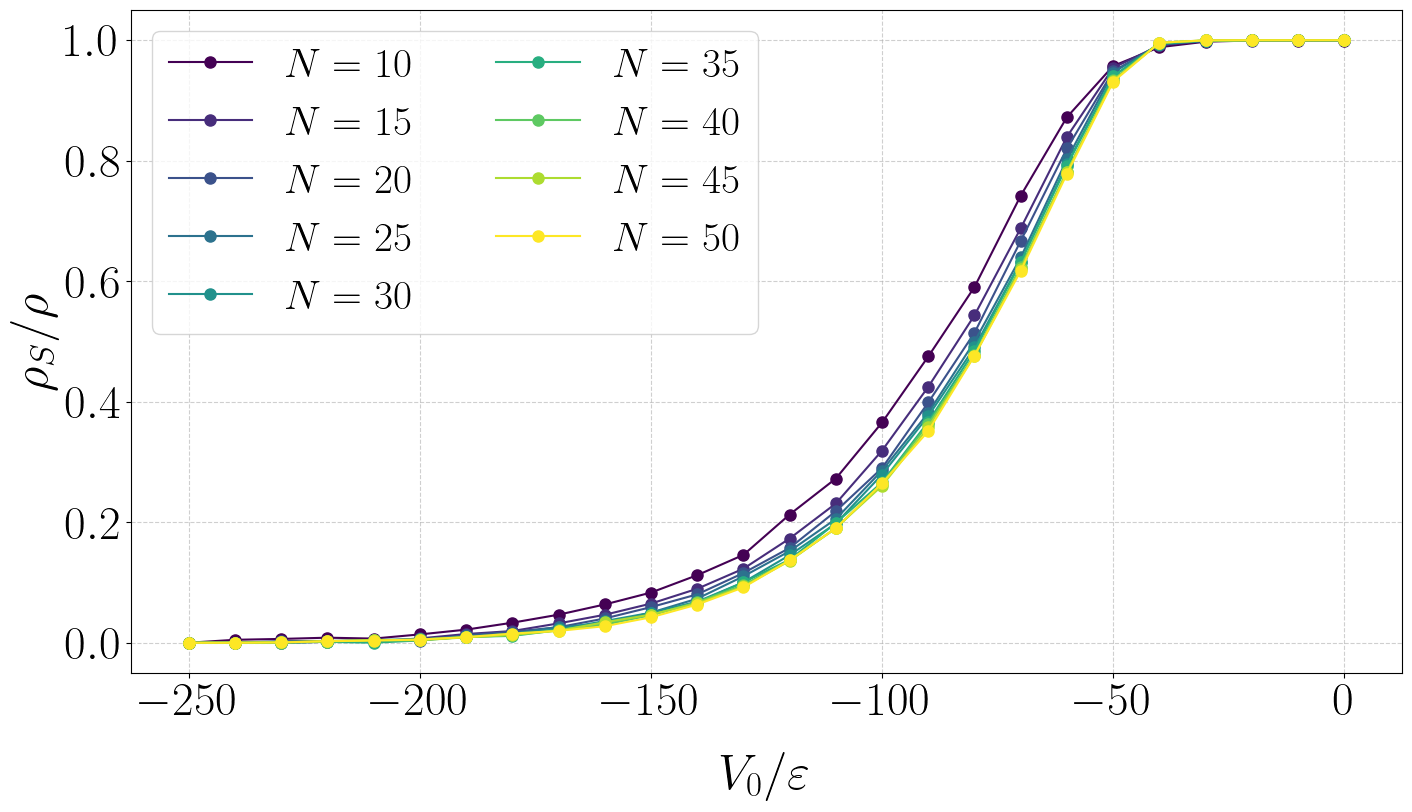

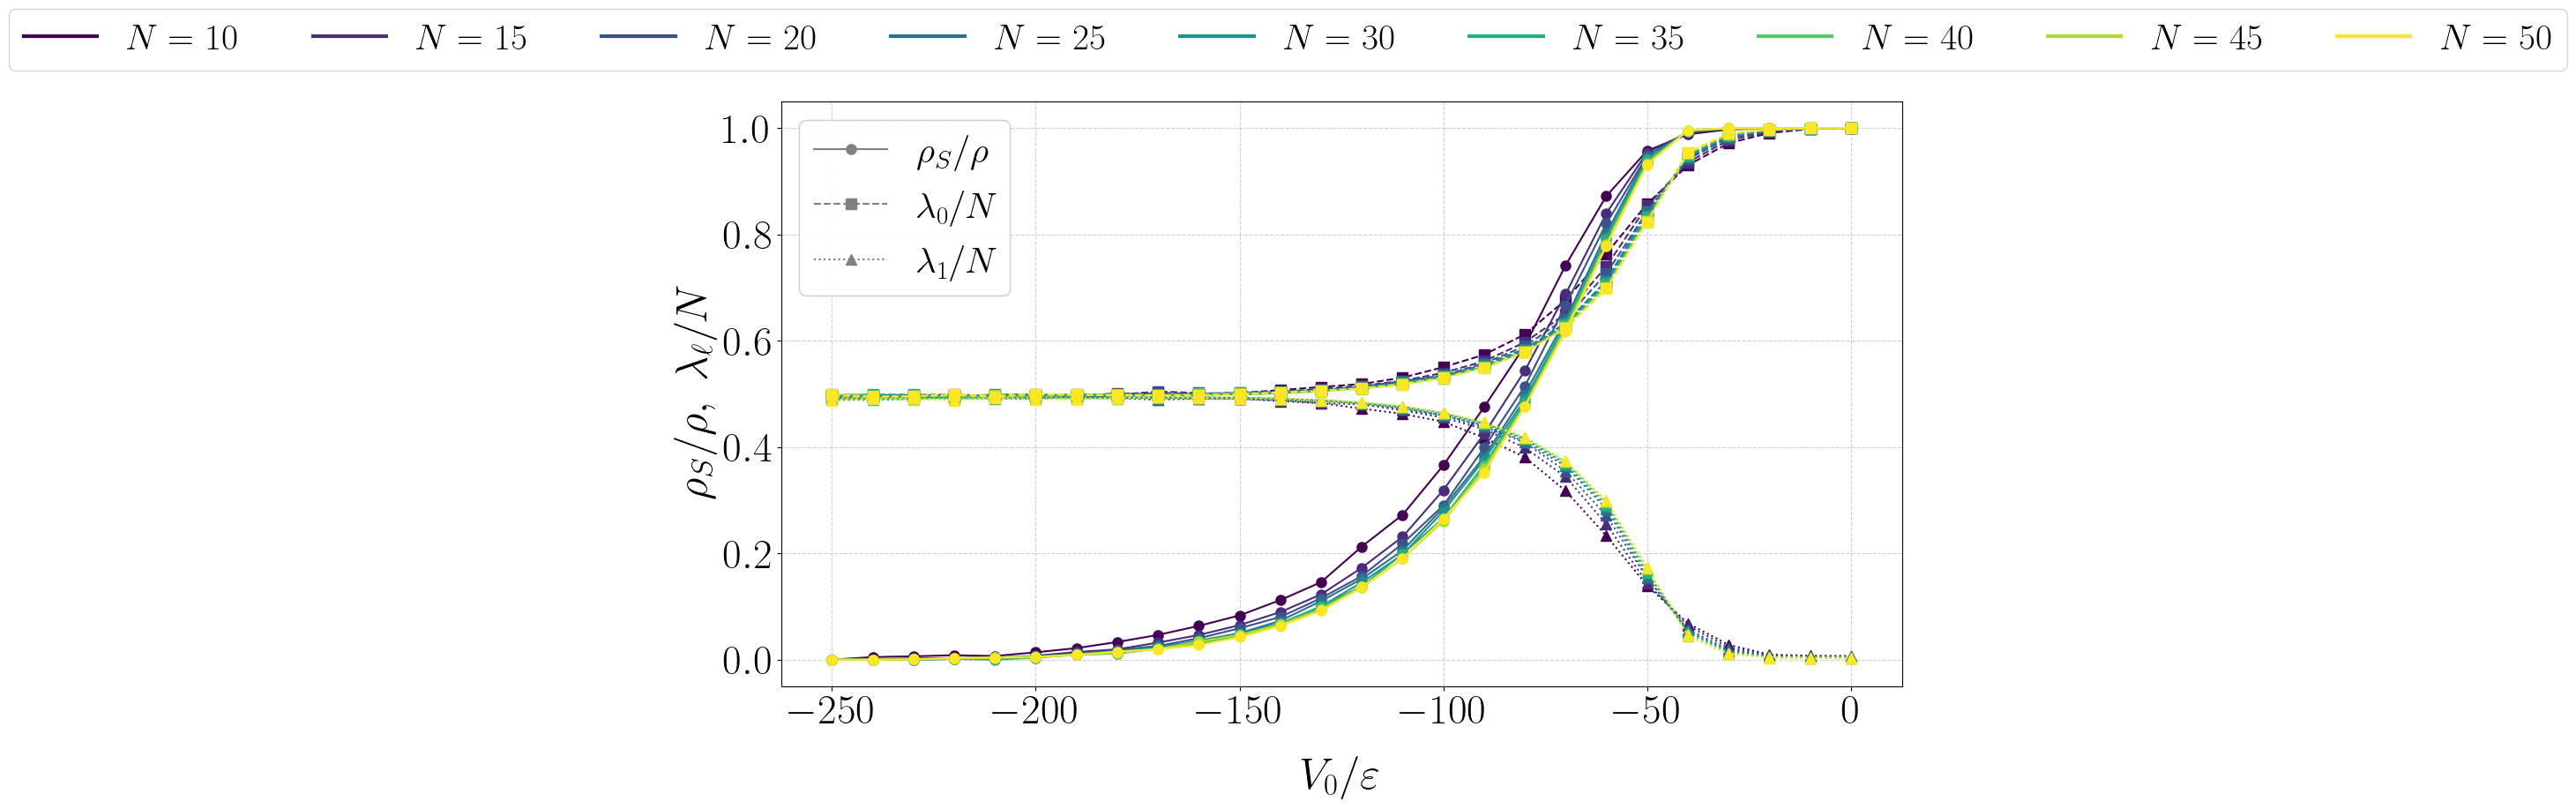

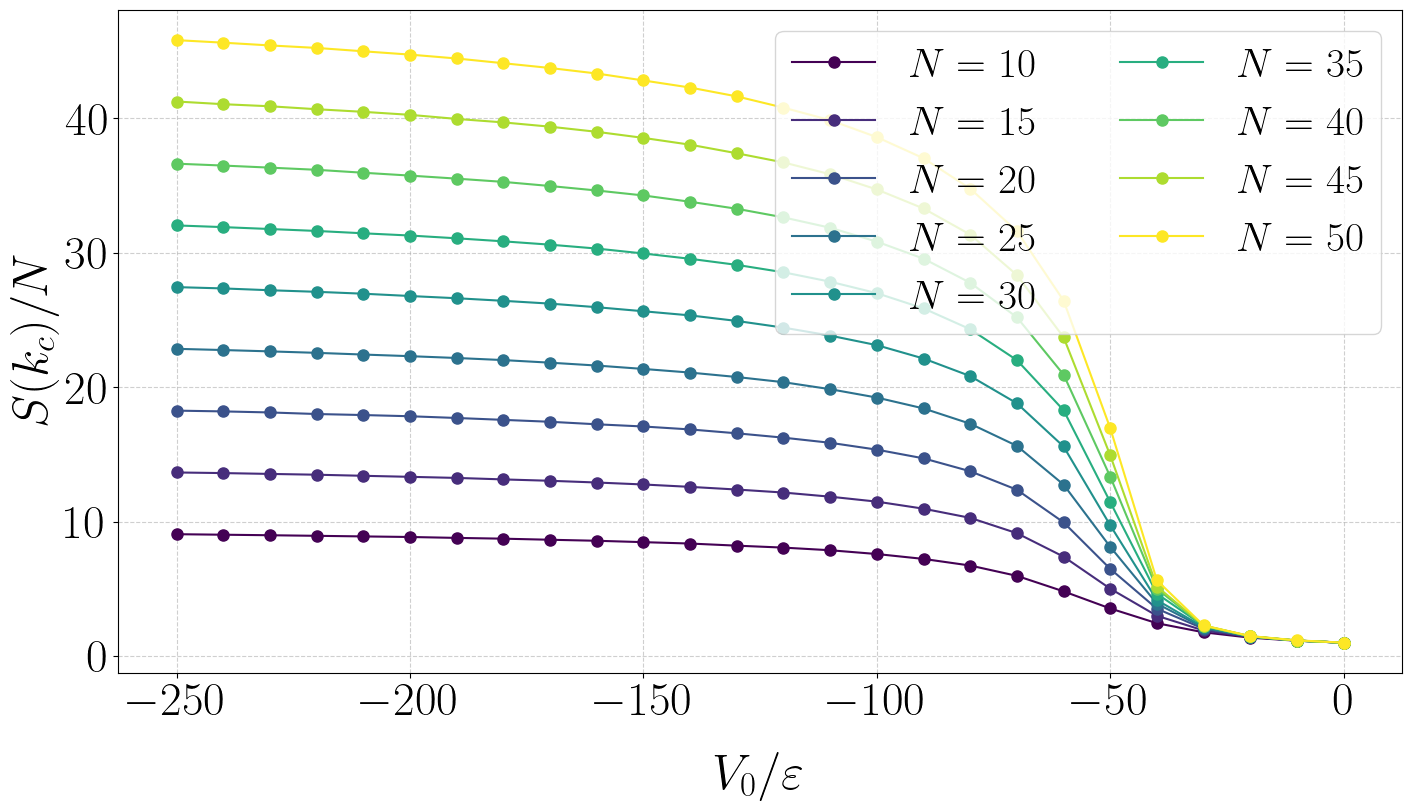

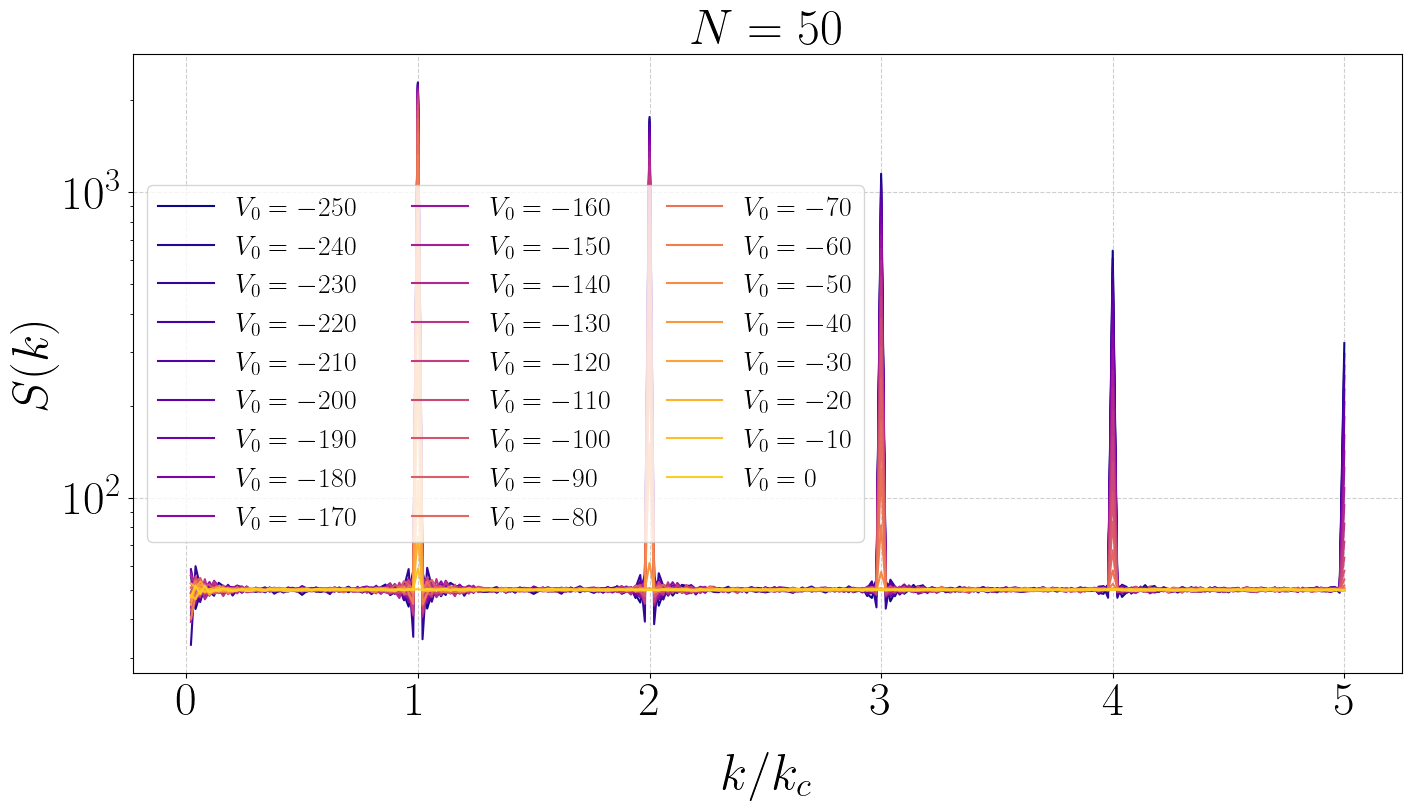

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import os

plt.rcParams.update({
    "pgf.texsystem": "pdflatex",
    "font.family": "serif",
    "font.size": 36,
    "axes.titlesize": 36,
    "axes.labelsize": 36,
    "xtick.labelsize": 34,
    "ytick.labelsize": 34,
    "legend.fontsize": 30,
    "figure.titlesize": 36,
    "text.usetex": True,
    "pgf.rcfonts": False,
})

# ------------------- DATA LOCATION -------------------

root = r"C:\Users\marta\Downloads\Cavity_mediated_interaction_TFM_restructured(2)"
base_vmc = os.path.join(root, "numpy_arrays_VMC", "constant_density_1.0")
base_dmc = os.path.join(root, "numpy_arrays_DMC", "constant_density_1.0")

# Which estimator to plot:
#   "vmc"          -> VMC data (observables of the trial wavefunction)
#   "dmc"          -> DMC mixed estimator
#   "extrapolated" -> 2 * DMC - VMC (first-order correction of the mixed-estimator bias)
estimator = "vmc"

# DMC run parameters (part of the DMC file names)
n_walkers = 200
dtau = 0.0010
n_steps = 3000
dmc_suffix = "IS"                              # importance sampling

density = 1.0                                  # rho; L = N / density
Ns_list = [10, 15, 20, 25, 30, 35, 40, 45, 50]
V0_kac_list = np.arange(0.0, -251.0, -10.0)    # Kac couplings V0_kac = N * V0 (bare)

# Interval over which hist_1D was binned in metropolis():
#   compute_zoom = true  -> one cavity period [-0.5, 0.5)   (interval = 1.0)
#   compute_zoom = false -> full box [-L/2, L/2)            (interval = L)
compute_zoom = True


def get_L(num_part):
    return num_part / density


def load_array(kind, num_part, V0_kac):
    """Load hist_1D, obdm or SSF for (N, V0_kac) with the chosen estimator.

    VMC folder : <kind>/V0=<V0>/<kind>_<N>_<V0>_<L>.npy
    DMC folder : <dir>/V0=<V0>/<pre>[_extrap]_<n_walkers>_<dtau>_<N>_<n_steps>_<V0>_<L>_<suffix>.npy
                 (hist_1D is stored as hist_1d/ with prefix hist1d; "_extrap" = 2*DMC - VMC
                 computed by the DMC run itself, "_vmc_" = the VMC of that same run).
    """
    L = get_L(num_part)
    V0 = V0_kac / num_part + 0.0               # bare V0 used in the simulation (+0.0 avoids "-0.000000")
    tail = f"{V0:.3f}_{L:.1f}"

    def _vmc_path():
        return os.path.join(base_vmc, kind, f"V0={V0:.3f}", f"{kind}_{num_part}_{tail}.npy")

    def _dmc_path(tag):                        # tag: "" (mixed estimator), "_extrap" or "_vmc"
        folder = "hist_1d" if kind == "hist_1D" else kind
        prefix = "hist1d" if kind == "hist_1D" else kind
        if tag == "_vmc":                      # VMC of the same DMC run (no DMC parameters in the name)
            name = f"{prefix}_vmc_{num_part}_{tail}.npy"
        else:
            name = f"{prefix}{tag}_{n_walkers}_{dtau:.4f}_{num_part}_{n_steps}_{tail}_{dmc_suffix}.npy"
        return os.path.join(base_dmc, folder, f"V0={V0:.3f}", name)

    def _load(path):
        if not os.path.isfile(path):
            raise FileNotFoundError(path)
        arr = np.load(path).real.astype(float)
        if kind == "hist_1D":                  # normalize n(x)
            interval = 1.0 if compute_zoom else L
            arr /= np.sum(arr) * interval / len(arr)
        return arr

    if estimator == "vmc":
        return _load(_vmc_path())
    if estimator == "dmc":
        return _load(_dmc_path(""))
    if estimator == "extrapolated":
        return _load(_dmc_path("_extrap"))
    raise ValueError(f"unknown estimator {estimator}")


def leggett_bound(num_part, V0_kac):
    """rho_S/rho upper bound (Leggett): 1 / (<n> <1/n>), averages over the binned interval."""
    L = get_L(num_part)
    n_x = load_array("hist_1D", num_part, V0_kac)
    interval = 1.0 if compute_zoom else L
    dx = interval / len(n_x)

    n_x /= np.sum(n_x * dx)                    # unit integral over the interval
    n_x = np.maximum(n_x, 1e-8)

    mean_n = np.sum(n_x * dx) / interval
    mean_inv_n = np.sum(dx / n_x) / interval
    return 1.0 / (mean_n * mean_inv_n)


def obdm_eigenvalues(num_part, V0_kac):
    """Eigenvalues of the one-body density matrix, sorted descending, divided by N.

    rho_1(x, x') is saved on [-L/2, L/2)^2 with nb bins per side, normalized so that
    the trace of rho_1 * dx equals N. It is averaged over lattice translations
    (x, x') -> (x + n, x' + n) before diagonalizing, which is exact and reduces noise.
    """
    L = get_L(num_part)
    rho1 = load_array("obdm", num_part, V0_kac)
    nb = rho1.shape[0]
    dx = L / nb

    n_cells = int(round(L))                    # number of cavity periods in the box
    if nb % n_cells == 0:
        shift = nb // n_cells
        rho1 = sum(np.roll(rho1, (n * shift, n * shift), axis=(0, 1))
                   for n in range(n_cells)) / n_cells

    lam = np.linalg.eigvalsh(rho1 * dx)[::-1]
    return lam / num_part, lam.sum()


# ------------------- COMPUTE rho_S/rho -------------------

results = {}
for num_part in Ns_list:
    V0_valid, rho_s = [], []
    for V0_kac in V0_kac_list:
        try:
            rho_s.append(leggett_bound(num_part, V0_kac))
            V0_valid.append(V0_kac)
        except FileNotFoundError:
            continue
    if rho_s:
        results[num_part] = (np.array(V0_valid), np.array(rho_s))
    else:
        print(f"No data found for N={num_part}")

# ------------------- COMPUTE OBDM EIGENVALUES -------------------

obdm_results = {}
for num_part in Ns_list:
    V0_valid, lam0, lam1 = [], [], []
    for V0_kac in V0_kac_list:
        try:
            lam, trace = obdm_eigenvalues(num_part, V0_kac)
        except FileNotFoundError:
            continue
        V0_valid.append(V0_kac)
        lam0.append(lam[0])
        lam1.append(lam[1])
        print(f"N={num_part:3d}  V0_kac={V0_kac:8.2f}  trace={trace:.3f} (should be {num_part})  "
              f"lambda_0..3/N = {np.round(lam[:4], 4)}")
    if V0_valid:
        obdm_results[num_part] = (np.array(V0_valid), np.array(lam0), np.array(lam1))
    else:
        print(f"No OBDM data found for N={num_part}")

print("\nN, V0_kac, rho_S/rho")
for num_part, (V0_valid, rho_s) in results.items():
    for V0, r in zip(V0_valid, rho_s):
        print(f"{num_part:3d}  {V0:8.2f}  {r:.5f}")

# ------------------- PLOT: all N on one axes -------------------

Ns_with_data = sorted(results.keys())
fig, ax = plt.subplots(figsize=(15, 9))
colors = plt.cm.viridis(np.linspace(0, 1, max(len(Ns_with_data), 2)))

for color, num_part in zip(colors, Ns_with_data):
    V0_valid, rho_s = results[num_part]
    ax.plot(V0_valid, rho_s, "-o", color=color, markersize=8, linewidth=1.5,
            label=fr"$N={num_part}$")

ax.set_xlabel(r"$V_0/\varepsilon$", labelpad=20)
ax.set_ylabel(r"$\rho_S/\rho$")
ax.set_ylim(-0.05, 1.05)
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(ncol=2)
plt.tight_layout()

os.makedirs("final_imag", exist_ok=True)
plt.savefig(f"final_imag/rhos_vs_V0_leggett_{estimator}.pdf", dpi=600, bbox_inches="tight")

# ------------------- PLOT: rho_S/rho together with the OBDM eigenvalues -------------------
#   solid  + circles   : rho_S/rho (Leggett bound)
#   dashed + squares   : lambda_0 / N  (largest OBDM eigenvalue)
#   dotted + triangles : lambda_1 / N  (second eigenvalue; -> 1/2 signals Z2 fragmentation)

from matplotlib.lines import Line2D

Ns_all = sorted(set(results) | set(obdm_results))
fig2, ax2 = plt.subplots(figsize=(15, 9))
colors2 = plt.cm.viridis(np.linspace(0, 1, max(len(Ns_all), 2)))

for color, num_part in zip(colors2, Ns_all):
    if num_part in results:
        V0_valid, rho_s = results[num_part]
        ax2.plot(V0_valid, rho_s, "-o", color=color, markersize=8, linewidth=1.5)
    if num_part in obdm_results:
        V0_valid, lam0, lam1 = obdm_results[num_part]
        ax2.plot(V0_valid, lam0, "--s", color=color, markersize=8, linewidth=1.5)
        ax2.plot(V0_valid, lam1, ":^", color=color, markersize=8, linewidth=1.5)

style_handles = [
    Line2D([0], [0], color="gray", linestyle="-",  marker="o", markersize=8, label=r"$\rho_S/\rho$"),
    Line2D([0], [0], color="gray", linestyle="--", marker="s", markersize=8, label=r"$\lambda_0/N$"),
    Line2D([0], [0], color="gray", linestyle=":",  marker="^", markersize=8, label=r"$\lambda_1/N$"),
]
N_handles = [Line2D([0], [0], color=c, linewidth=3, label=fr"$N={n}$")
             for c, n in zip(colors2, Ns_all)]
leg1 = ax2.legend(handles=style_handles, loc="upper left")
ax2.add_artist(leg1)
if len(Ns_all) > 1:
    fig2.legend(handles=N_handles, loc="upper center", bbox_to_anchor=(0.5, 1.08),
                ncol=len(Ns_all), frameon=True)

ax2.set_xlabel(r"$V_0/\varepsilon$", labelpad=20)
ax2.set_ylabel(r"$\rho_S/\rho,\ \lambda_\ell/N$")
ax2.set_ylim(-0.05, 1.05)
ax2.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig(f"final_imag/rhos_and_obdm_vs_V0_{estimator}.pdf", dpi=600, bbox_inches="tight")

# ------------------- STATIC STRUCTURE FACTOR -------------------
# S(k) = <|rho_k|^2>/N on k = 2 pi n / L, n = 1 ... 5L. The cavity wavevector k_c = 2 pi
# is entry n = L (index L - 1). S(k_c)/N -> <Theta_c^2 + Theta_s^2>, the self-organization
# order parameter squared; unlike lambda_0, it does not depend on which Z2 branch is sampled.

ssf_N = max(Ns_list)               # N used for the S(k) curves at several V0


def k_values(num_part):
    L = get_L(num_part)
    return 2 * np.pi / L * np.arange(1, int(5 * L) + 1)


ssf_results, ssf_curves = {}, {}
for num_part in Ns_list:
    L = get_L(num_part)
    i_c = int(round(L)) - 1                    # index of k = 2 pi
    V0_valid, S_c = [], []
    for V0_kac in V0_kac_list:
        try:
            S = load_array("SSF", num_part, V0_kac)
        except FileNotFoundError as e:
            print("missing:", e)
            continue
        V0_valid.append(V0_kac)
        S_c.append(S[i_c] / num_part)
        if num_part == ssf_N:
            ssf_curves[V0_kac] = S
    if V0_valid:
        ssf_results[num_part] = (np.array(V0_valid), np.array(S_c))

if ssf_results:
    # --- S(k_c)/N vs V0 for every N ---
    Ns_ssf = sorted(ssf_results)
    fig3, ax3 = plt.subplots(figsize=(15, 9))
    colors3 = plt.cm.viridis(np.linspace(0, 1, max(len(Ns_ssf), 2)))
    for color, num_part in zip(colors3, Ns_ssf):
        V0_valid, S_c = ssf_results[num_part]
        ax3.plot(V0_valid, S_c, "-o", color=color, markersize=8, linewidth=1.5,
                 label=fr"$N={num_part}$")
    ax3.set_xlabel(r"$V_0/\varepsilon$", labelpad=20)
    ax3.set_ylabel(r"$S(k_c)/N$")
    ax3.grid(True, linestyle="--", alpha=0.6)
    ax3.legend(ncol=2)
    plt.tight_layout()
    plt.savefig(f"final_imag/Skc_vs_V0_{estimator}.pdf", dpi=600, bbox_inches="tight")

if ssf_curves:
    # --- S(k) vs k/k_c for one N at several V0 ---
    fig4, ax4 = plt.subplots(figsize=(15, 9))
    V0_sorted = sorted(ssf_curves)
    colors4 = plt.cm.plasma(np.linspace(0, 0.9, max(len(V0_sorted), 2)))
    k_over_kc = k_values(ssf_N) / (2 * np.pi)
    for color, V0_kac in zip(colors4, V0_sorted):
        ax4.plot(k_over_kc, ssf_curves[V0_kac], "-", color=color, linewidth=1.5,
                 label=fr"$V_0={V0_kac:.0f}$")
    ax4.set_xlabel(r"$k/k_c$", labelpad=20)
    ax4.set_ylabel(r"$S(k)$")
    ax4.set_yscale("log")
    ax4.set_title(fr"$N={ssf_N}$")
    ax4.grid(True, linestyle="--", alpha=0.6)
    ax4.legend(ncol=3, fontsize=20)
    plt.tight_layout()
    plt.savefig(f"final_imag/Sk_N{ssf_N}_{estimator}.pdf", dpi=600, bbox_inches="tight")

plt.show()

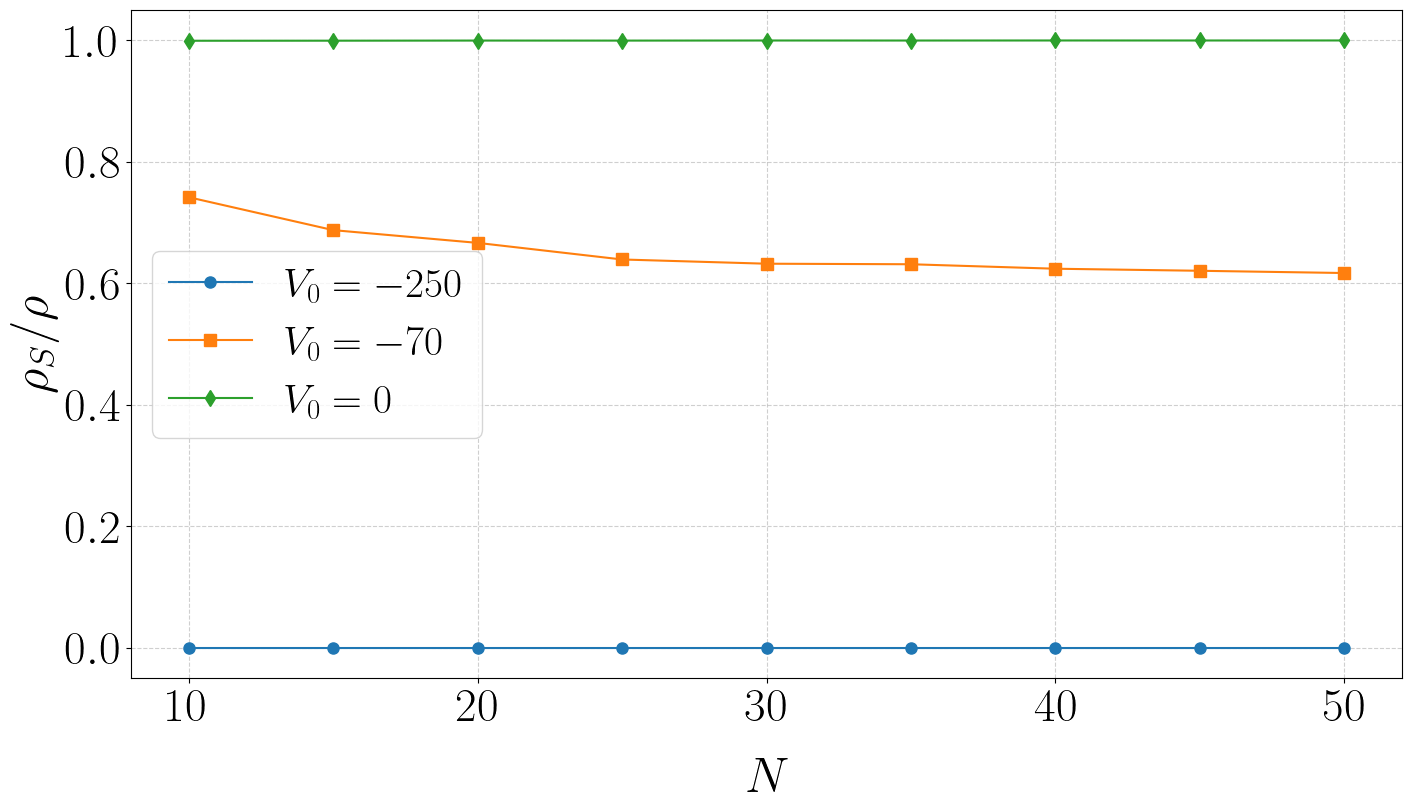

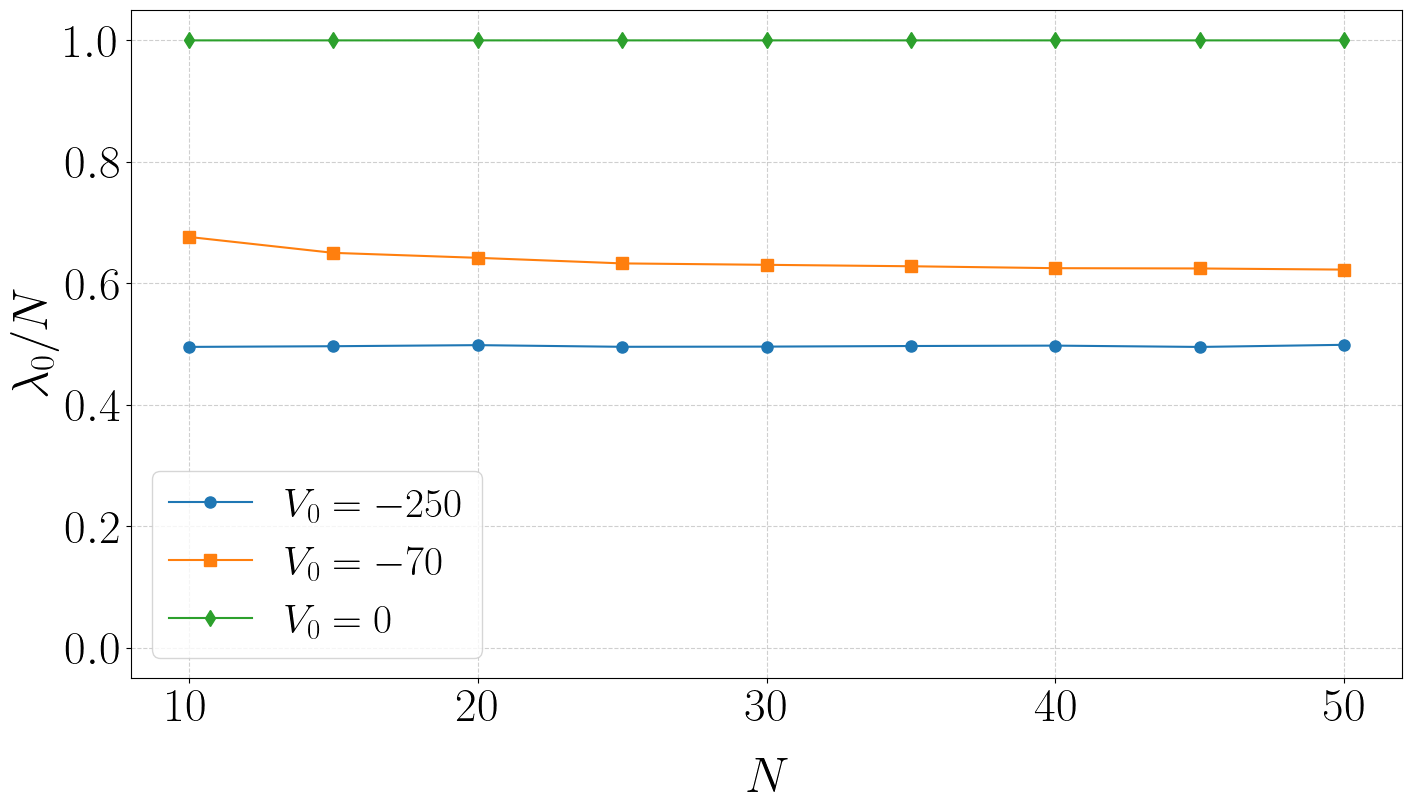

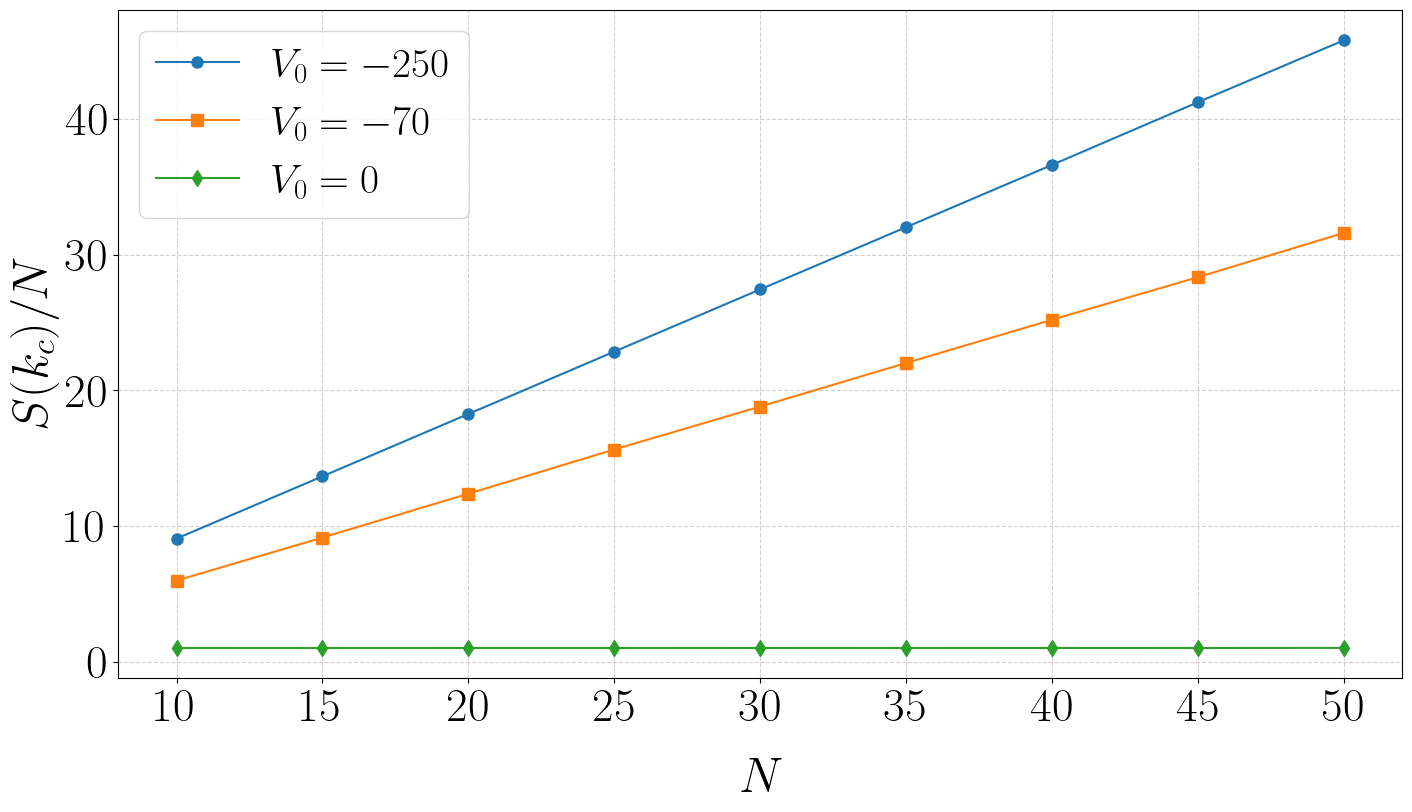

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import os

plt.rcParams.update({
    "pgf.texsystem": "pdflatex",
    "font.family": "serif",
    "font.size": 36,
    "axes.titlesize": 36,
    "axes.labelsize": 36,
    "xtick.labelsize": 34,
    "ytick.labelsize": 34,
    "legend.fontsize": 30,
    "figure.titlesize": 36,
    "text.usetex": True,
    "pgf.rcfonts": False,
})

# ------------------- DATA LOCATION -------------------

root = r"C:\Users\marta\Downloads\Cavity_mediated_interaction_TFM_restructured(2)"
base_vmc = os.path.join(root, "numpy_arrays_VMC", "constant_density_1.0")
base_dmc = os.path.join(root, "numpy_arrays_DMC", "constant_density_1.0")

# Which estimator to plot: "vmc", "dmc" or "extrapolated" (2 * DMC - VMC)
estimator = "vmc"

# DMC run parameters (part of the DMC file names)
n_walkers = 200
dtau = 0.0010
n_steps = 3000
dmc_suffix = "IS"                              # importance sampling

density = 1.0                                  # rho; L = N / density
Ns_list = list(range(10, 51, 5))
# Kac couplings V0_kac = N * V0 (bare). The simulated grid is multiples of 10, so -75 does not
# exist; -70 is the closest. Missing files are skipped.
V0_cases = [-250.0, -70.0, 0.0]

compute_zoom = True                            # hist_1D binned over one cavity period


def get_L(num_part):
    return num_part / density


def load_array(kind, num_part, V0_kac):
    """Load hist_1D, obdm or SSF for (N, V0_kac) with the chosen estimator.

    VMC folder : <kind>/V0=<V0>/<kind>_<N>_<V0>_<L>.npy
    DMC folder : <dir>/V0=<V0>/<pre>[_extrap]_<n_walkers>_<dtau>_<N>_<n_steps>_<V0>_<L>_<suffix>.npy
                 (hist_1D is stored as hist_1d/ with prefix hist1d; "_extrap" = 2*DMC - VMC
                 computed by the DMC run itself, "_vmc_" = the VMC of that same run).
    """
    L = get_L(num_part)
    V0 = V0_kac / num_part + 0.0               # bare V0 used in the simulation (+0.0 avoids "-0.000000")
    tail = f"{V0:.3f}_{L:.1f}"

    def _vmc_path():
        return os.path.join(base_vmc, kind, f"V0={V0:.3f}", f"{kind}_{num_part}_{tail}.npy")

    def _dmc_path(tag):                        # tag: "" (mixed estimator), "_extrap" or "_vmc"
        folder = "hist_1d" if kind == "hist_1D" else kind
        prefix = "hist1d" if kind == "hist_1D" else kind
        if tag == "_vmc":                      # VMC of the same DMC run (no DMC parameters in the name)
            name = f"{prefix}_vmc_{num_part}_{tail}.npy"
        else:
            name = f"{prefix}{tag}_{n_walkers}_{dtau:.4f}_{num_part}_{n_steps}_{tail}_{dmc_suffix}.npy"
        return os.path.join(base_dmc, folder, f"V0={V0:.3f}", name)

    def _load(path):
        if not os.path.isfile(path):
            raise FileNotFoundError(path)
        arr = np.load(path).real.astype(float)
        if kind == "hist_1D":                  # normalize n(x)
            interval = 1.0 if compute_zoom else L
            arr /= np.sum(arr) * interval / len(arr)
        return arr

    if estimator == "vmc":
        return _load(_vmc_path())
    if estimator == "dmc":
        return _load(_dmc_path(""))
    if estimator == "extrapolated":
        return _load(_dmc_path("_extrap"))
    raise ValueError(f"unknown estimator {estimator}")


def leggett_bound(num_part, V0_kac):
    """rho_S/rho upper bound (Leggett): 1 / (<n> <1/n>), averages over the binned interval."""
    L = get_L(num_part)
    n_x = load_array("hist_1D", num_part, V0_kac)
    interval = 1.0 if compute_zoom else L
    dx = interval / len(n_x)

    n_x /= np.sum(n_x * dx)
    n_x = np.maximum(n_x, 1e-8)

    mean_n = np.sum(n_x * dx) / interval
    mean_inv_n = np.sum(dx / n_x) / interval
    return 1.0 / (mean_n * mean_inv_n)


def obdm_eigenvalues(num_part, V0_kac):
    """OBDM eigenvalues / N (descending), translation-averaged over the lattice."""
    L = get_L(num_part)
    rho1 = load_array("obdm", num_part, V0_kac)
    nb = rho1.shape[0]
    dx = L / nb

    n_cells = int(round(L))
    if nb % n_cells == 0:
        shift = nb // n_cells
        rho1 = sum(np.roll(rho1, (n * shift, n * shift), axis=(0, 1))
                   for n in range(n_cells)) / n_cells

    lam = np.linalg.eigvalsh(rho1 * dx)[::-1]
    return lam / num_part


def S_kc(num_part, V0_kac):
    """S(k_c)/N; k_c = 2 pi is entry n = L (index L - 1) of the saved S(k)."""
    i_c = int(round(get_L(num_part))) - 1
    return load_array("SSF", num_part, V0_kac)[i_c] / num_part


# ------------------- COMPUTE vs N FOR EACH V0 -------------------

three = {}
for V0_kac in V0_cases:
    Ns_ok, rho_s, lam0, lam1, skc = [], [], [], [], []
    for num_part in Ns_list:
        try:
            lam = obdm_eigenvalues(num_part, V0_kac)
            rho_s.append(leggett_bound(num_part, V0_kac))
            skc.append(S_kc(num_part, V0_kac))
        except FileNotFoundError:
            continue
        Ns_ok.append(num_part)
        lam0.append(lam[0])
        lam1.append(lam[1])
    if Ns_ok:
        three[V0_kac] = tuple(np.array(a) for a in (Ns_ok, rho_s, lam0, lam1, skc))
    else:
        print(f"No data found for V0_kac={V0_kac}")

# ------------------- PLOTS: N on the x axis, one curve per V0 -------------------

markers = ["o", "s", "d"]
panels = [
    (1, r"$\rho_S/\rho$",   "rhos",  (-0.05, 1.05)),
    (2, r"$\lambda_0/N$",   "lam0",  (-0.05, 1.05)),
    (4, r"$S(k_c)/N$",      "Skc",   None),
]

os.makedirs("final_imag", exist_ok=True)
for idx, ylabel, tag, ylim in panels:
    fig, ax = plt.subplots(figsize=(15, 9))
    for marker, (V0_kac, data) in zip(markers, three.items()):
        ax.plot(data[0], data[idx], "-" + marker, markersize=8, linewidth=1.5,
                label=fr"$V_0={V0_kac:.0f}$")
    ax.set_xlabel(r"$N$", labelpad=20)
    ax.set_ylabel(ylabel)
    if ylim:
        ax.set_ylim(*ylim)
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend()
    plt.tight_layout()
    plt.savefig(f"final_imag/{tag}_vs_N_three_V0_{estimator}.pdf", dpi=600, bbox_inches="tight")

plt.show()



V0_kac, rho_S/rho, lambda_0/N, lambda_1/N, S(k_c)/N^2   (N -> infinity)
    0.00  0.99996  1.00000  0.00222  0.00010
  -10.00  0.99994  0.99996  0.00179  0.00039
  -20.00  0.99992  0.99956  0.00137  0.00109
  -30.00  1.00018  0.99572  0.00476  0.00974
  -40.00  0.99802  0.96253  0.03790  0.06983
  -50.00  0.92019  0.80989  0.18804  0.34272
  -60.00  0.75000  0.67866  0.31911  0.55038
  -70.00  0.58604  0.61034  0.38724  0.63999
  -80.00  0.44707  0.56955  0.42545  0.70191
  -90.00  0.32373  0.54227  0.45297  0.74334
 -100.00  0.23995  0.52607  0.46911  0.77431
 -110.00  0.16898  0.51305  0.48086  0.79933
 -120.00  0.11864  0.50766  0.48415  0.81832
 -130.00  0.07546  0.50466  0.48858  0.83430
 -140.00  0.05293  0.50076  0.49144  0.84702
 -150.00  0.03375  0.49752  0.49311  0.85830
 -160.00  0.02370  0.49670  0.49045  0.86963
 -170.00  0.01505  0.49408  0.49633  0.87716
 -180.00  0.00967  0.49897  0.49092  0.88433
 -190.00  0.00642  0.50017  0.48806  0.89027
 -200.00  0.00554  0.49874 

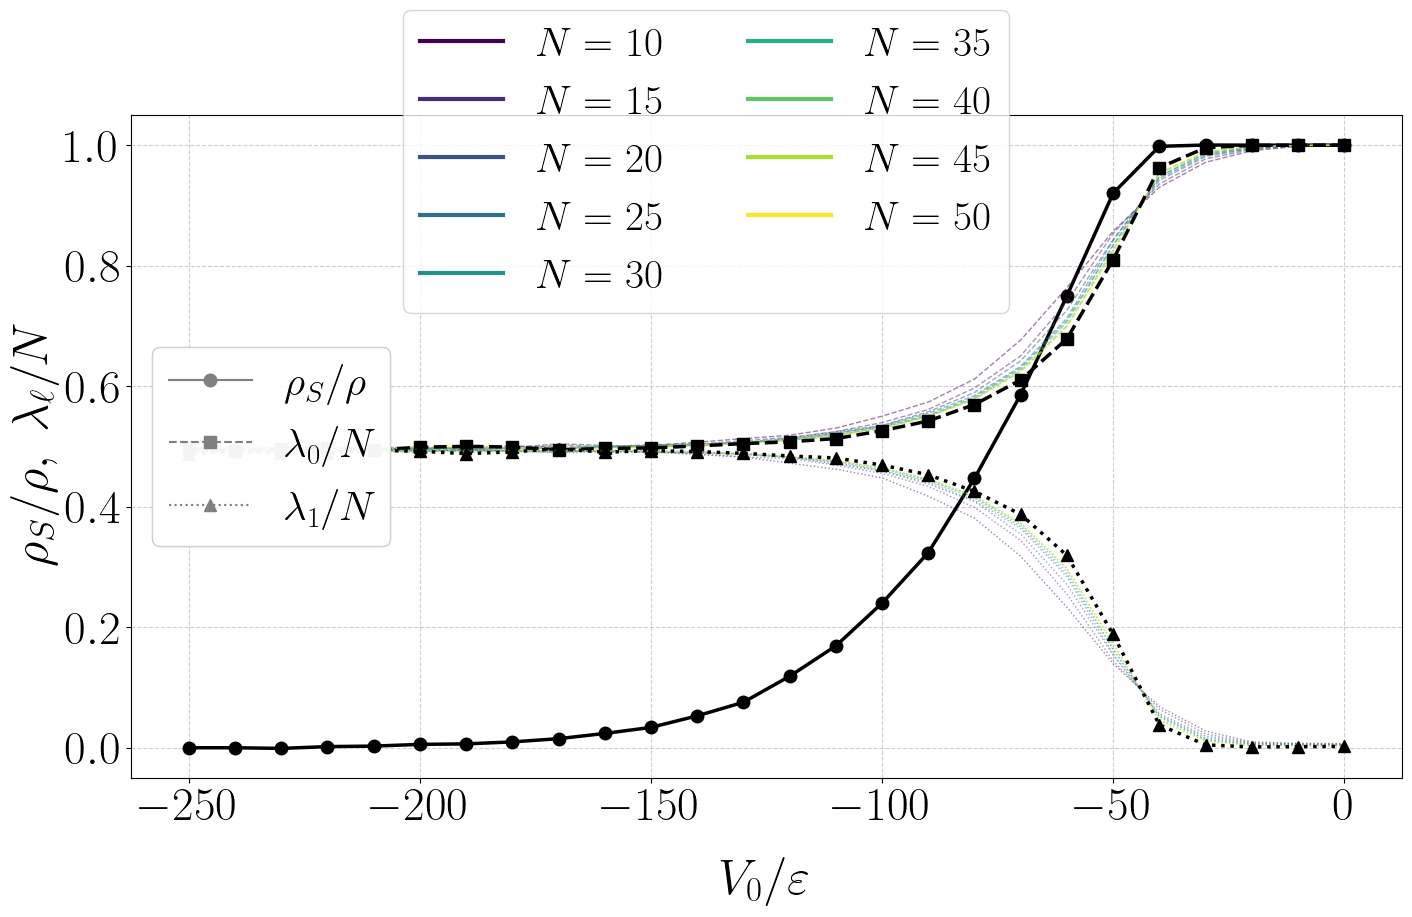

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os

plt.rcParams.update({
    "pgf.texsystem": "pdflatex",
    "font.family": "serif",
    "font.size": 36,
    "axes.titlesize": 36,
    "axes.labelsize": 36,
    "xtick.labelsize": 34,
    "ytick.labelsize": 34,
    "legend.fontsize": 30,
    "figure.titlesize": 36,
    "text.usetex": True,
    "pgf.rcfonts": False,
})

# ------------------- DATA LOCATION -------------------

root = r"C:\Users\marta\Downloads\Cavity_mediated_interaction_TFM_restructured(2)"
base_vmc = os.path.join(root, "numpy_arrays_VMC", "constant_density_1.0")
base_dmc = os.path.join(root, "numpy_arrays_DMC", "constant_density_1.0")

# Which estimator to plot: "vmc", "dmc" or "extrapolated" (2 * DMC - VMC)
estimator = "vmc"

# DMC run parameters (part of the DMC file names)
n_walkers = 200
dtau = 0.0010
n_steps = 3000
dmc_suffix = "IS"                              # importance sampling

density = 1.0                                  # rho; L = N / density
Ns_list = list(range(10, 51, 5))
V0_kac_list = np.arange(0.0, -251.0, -10.0)    # Kac couplings V0_kac = N * V0 (bare)

# Extrapolation N -> infinity: linear fit in 1/N using the sizes N >= N_min_fit
N_min_fit = 20
fit_deg = 1

compute_zoom = True                            # hist_1D binned over one cavity period


def get_L(num_part):
    return num_part / density


def load_array(kind, num_part, V0_kac):
    """Load hist_1D, obdm or SSF for (N, V0_kac) with the chosen estimator.

    VMC folder : <kind>/V0=<V0>/<kind>_<N>_<V0>_<L>.npy
    DMC folder : <dir>/V0=<V0>/<pre>[_extrap]_<n_walkers>_<dtau>_<N>_<n_steps>_<V0>_<L>_<suffix>.npy
                 (hist_1D is stored as hist_1d/ with prefix hist1d; "_extrap" = 2*DMC - VMC
                 computed by the DMC run itself, "_vmc_" = the VMC of that same run).
    """
    L = get_L(num_part)
    V0 = V0_kac / num_part + 0.0               # bare V0 used in the simulation (+0.0 avoids "-0.000000")
    tail = f"{V0:.3f}_{L:.1f}"

    def _vmc_path():
        return os.path.join(base_vmc, kind, f"V0={V0:.3f}", f"{kind}_{num_part}_{tail}.npy")

    def _dmc_path(tag):                        # tag: "" (mixed estimator), "_extrap" or "_vmc"
        folder = "hist_1d" if kind == "hist_1D" else kind
        prefix = "hist1d" if kind == "hist_1D" else kind
        if tag == "_vmc":                      # VMC of the same DMC run (no DMC parameters in the name)
            name = f"{prefix}_vmc_{num_part}_{tail}.npy"
        else:
            name = f"{prefix}{tag}_{n_walkers}_{dtau:.4f}_{num_part}_{n_steps}_{tail}_{dmc_suffix}.npy"
        return os.path.join(base_dmc, folder, f"V0={V0:.3f}", name)

    def _load(path):
        if not os.path.isfile(path):
            raise FileNotFoundError(path)
        arr = np.load(path).real.astype(float)
        if kind == "hist_1D":                  # normalize n(x)
            interval = 1.0 if compute_zoom else L
            arr /= np.sum(arr) * interval / len(arr)
        return arr

    if estimator == "vmc":
        return _load(_vmc_path())
    if estimator == "dmc":
        return _load(_dmc_path(""))
    if estimator == "extrapolated":
        return _load(_dmc_path("_extrap"))
    raise ValueError(f"unknown estimator {estimator}")


def leggett_bound(num_part, V0_kac):
    """rho_S/rho upper bound (Leggett): 1 / (<n> <1/n>), averages over the binned interval."""
    L = get_L(num_part)
    n_x = load_array("hist_1D", num_part, V0_kac)
    interval = 1.0 if compute_zoom else L
    dx = interval / len(n_x)

    n_x /= np.sum(n_x * dx)
    n_x = np.maximum(n_x, 1e-8)

    mean_n = np.sum(n_x * dx) / interval
    mean_inv_n = np.sum(dx / n_x) / interval
    return 1.0 / (mean_n * mean_inv_n)


def obdm_eigenvalues(num_part, V0_kac):
    """OBDM eigenvalues / N (descending), translation-averaged over the lattice."""
    L = get_L(num_part)
    rho1 = load_array("obdm", num_part, V0_kac)
    nb = rho1.shape[0]
    dx = L / nb

    n_cells = int(round(L))
    if nb % n_cells == 0:
        shift = nb // n_cells
        rho1 = sum(np.roll(rho1, (n * shift, n * shift), axis=(0, 1))
                   for n in range(n_cells)) / n_cells

    lam = np.linalg.eigvalsh(rho1 * dx)[::-1]
    return lam / num_part


def S_kc(num_part, V0_kac):
    """S(k_c)/N^2 = order parameter squared (finite as N -> infinity; S(k_c) itself grows ~N^2).

    k_c = 2 pi is entry n = L (index L - 1) of the saved S(k).
    """
    i_c = int(round(get_L(num_part))) - 1
    return load_array("SSF", num_part, V0_kac)[i_c] / num_part**2


# ------------------- COMPUTE vs N AND EXTRAPOLATE 1/N -> 0 -------------------

def extrapolate(Ns, y, deg=fit_deg, n_min=N_min_fit):
    """Polynomial fit of y vs 1/N; returns the value at 1/N = 0 (the intercept)."""
    Ns, y = np.asarray(Ns, float), np.asarray(y, float)
    m = Ns >= n_min
    return np.polyfit(1.0 / Ns[m], y[m], deg)[-1]


finite = {}                                    # finite[V0_kac] = (Ns, rho_s, lam0, S_kc/N^2, lam1)
extrap = {"rhos": [], "lam0": [], "lam1": [], "Skc": []}
V0_ok = []
for V0_kac in V0_kac_list:
    Ns_ok, rho_s, lam0, lam1, skc = [], [], [], [], []
    for num_part in Ns_list:
        try:
            lam = obdm_eigenvalues(num_part, V0_kac)
            rho_s.append(leggett_bound(num_part, V0_kac))
            skc.append(S_kc(num_part, V0_kac))
        except FileNotFoundError:
            continue
        Ns_ok.append(num_part)
        lam0.append(lam[0])
        lam1.append(lam[1])
    if sum(np.array(Ns_ok) >= N_min_fit) <= fit_deg:
        print(f"Not enough sizes for V0_kac={V0_kac}")
        continue
    finite[V0_kac] = (np.array(Ns_ok), np.array(rho_s), np.array(lam0), np.array(skc), np.array(lam1))
    V0_ok.append(V0_kac)
    extrap["rhos"].append(extrapolate(Ns_ok, rho_s))
    extrap["lam0"].append(extrapolate(Ns_ok, lam0))
    extrap["lam1"].append(extrapolate(Ns_ok, lam1))
    extrap["Skc"].append(extrapolate(Ns_ok, skc))
V0_ok = np.array(V0_ok)

print("\nV0_kac, rho_S/rho, lambda_0/N, lambda_1/N, S(k_c)/N^2   (N -> infinity)")
for i, V0 in enumerate(V0_ok):
    print(f"{V0:8.2f}  {extrap['rhos'][i]:.5f}  {extrap['lam0'][i]:.5f}  {extrap['lam1'][i]:.5f}  "
          f"{extrap['Skc'][i]:.5f}")

# ------------------- PLOTS vs V0: finite N (thin) and N -> infinity (thick) -------------------
# rho_S/rho and lambda_0/N (+ lambda_1/N) go on one shared axes; S(k_c)/N^2 on its own.

from matplotlib.lines import Line2D

Ns_plot = sorted({n for d in finite.values() for n in d[0]})
colors = plt.cm.viridis(np.linspace(0, 1, max(len(Ns_plot), 2)))
os.makedirs("final_imag", exist_ok=True)


def _series(idx):
    """xs, ys per N for finite[...][idx], plus the N -> infinity curve for the matching tag."""
    out = []
    for color, num_part in zip(colors, Ns_plot):
        xs, ys = [], []
        for V0_kac, d in finite.items():
            if num_part in d[0]:
                xs.append(V0_kac)
                ys.append(d[idx][list(d[0]).index(num_part)])
        out.append((color, xs, ys))
    return out


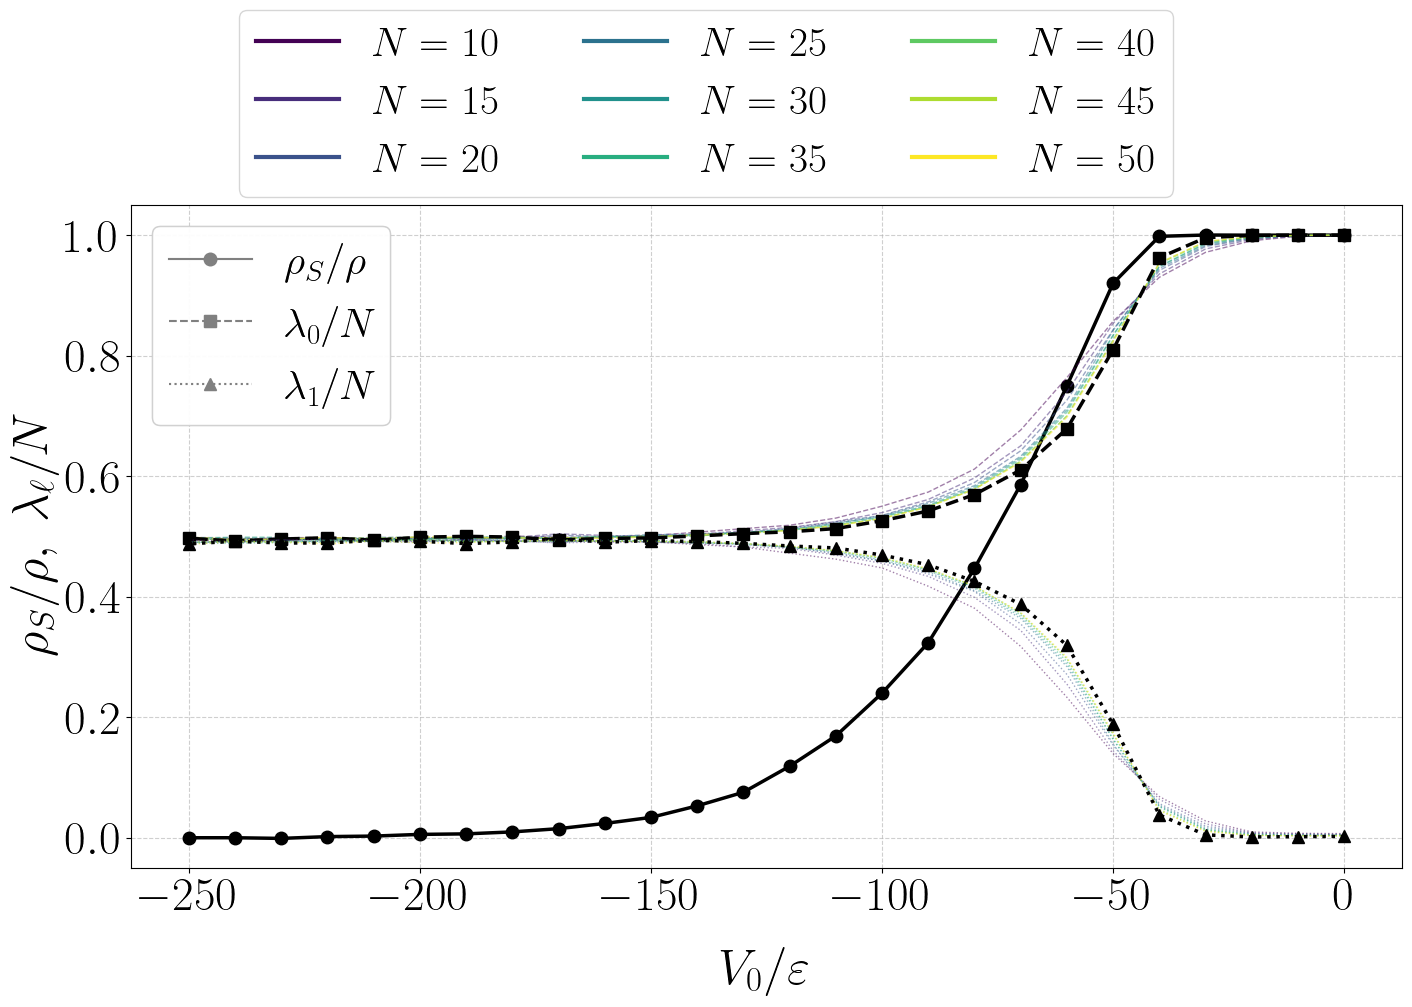

In [24]:
# --- combined figure: rho_S/rho (solid circles) + lambda_0/N, lambda_1/N (dashed/dotted) ---
fig, ax = plt.subplots(figsize=(15, 9))
# for color, xs, ys in _series(1):                      # rho_S/rho
#     ax.plot(xs, ys, "-", color=color, linewidth=1, alpha=0.5)
ax.plot(V0_ok, extrap["rhos"], "-o", color="k", markersize=9, linewidth=2.5)
for color, xs, ys in _series(2):                       # lambda_0/N
    ax.plot(xs, ys, "--", color=color, linewidth=1, alpha=0.5)
ax.plot(V0_ok, extrap["lam0"], "--s", color="k", markersize=9, linewidth=2.5)
for color, xs, ys in _series(4):                       # lambda_1/N
    ax.plot(xs, ys, ":", color=color, linewidth=1, alpha=0.5)
ax.plot(V0_ok, extrap["lam1"], ":^", color="k", markersize=9, linewidth=2.5)

style_handles = [
    Line2D([0], [0], color="gray", linestyle="-",  marker="o", markersize=9, label=r"$\rho_S/\rho$"),
    Line2D([0], [0], color="gray", linestyle="--", marker="s", markersize=9, label=r"$\lambda_0/N$"),
    Line2D([0], [0], color="gray", linestyle=":",  marker="^", markersize=9, label=r"$\lambda_1/N$"),
]
N_handles = [Line2D([0], [0], color=c, linewidth=3, label=fr"$N={n}$")
             for c, n in zip(colors, Ns_plot)]
leg1 = ax.legend(handles=style_handles, loc="upper left")
ax.add_artist(leg1)
fig.legend(handles=N_handles, loc="upper center", bbox_to_anchor=(0.5, 1.18),
           ncol=3, frameon=True)

ax.set_xlabel(r"$V_0/\varepsilon$", labelpad=20)
ax.set_ylabel(r"$\rho_S/\rho,\ \lambda_\ell/N$")
ax.set_ylim(-0.05, 1.05)
ax.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()

plt.show()

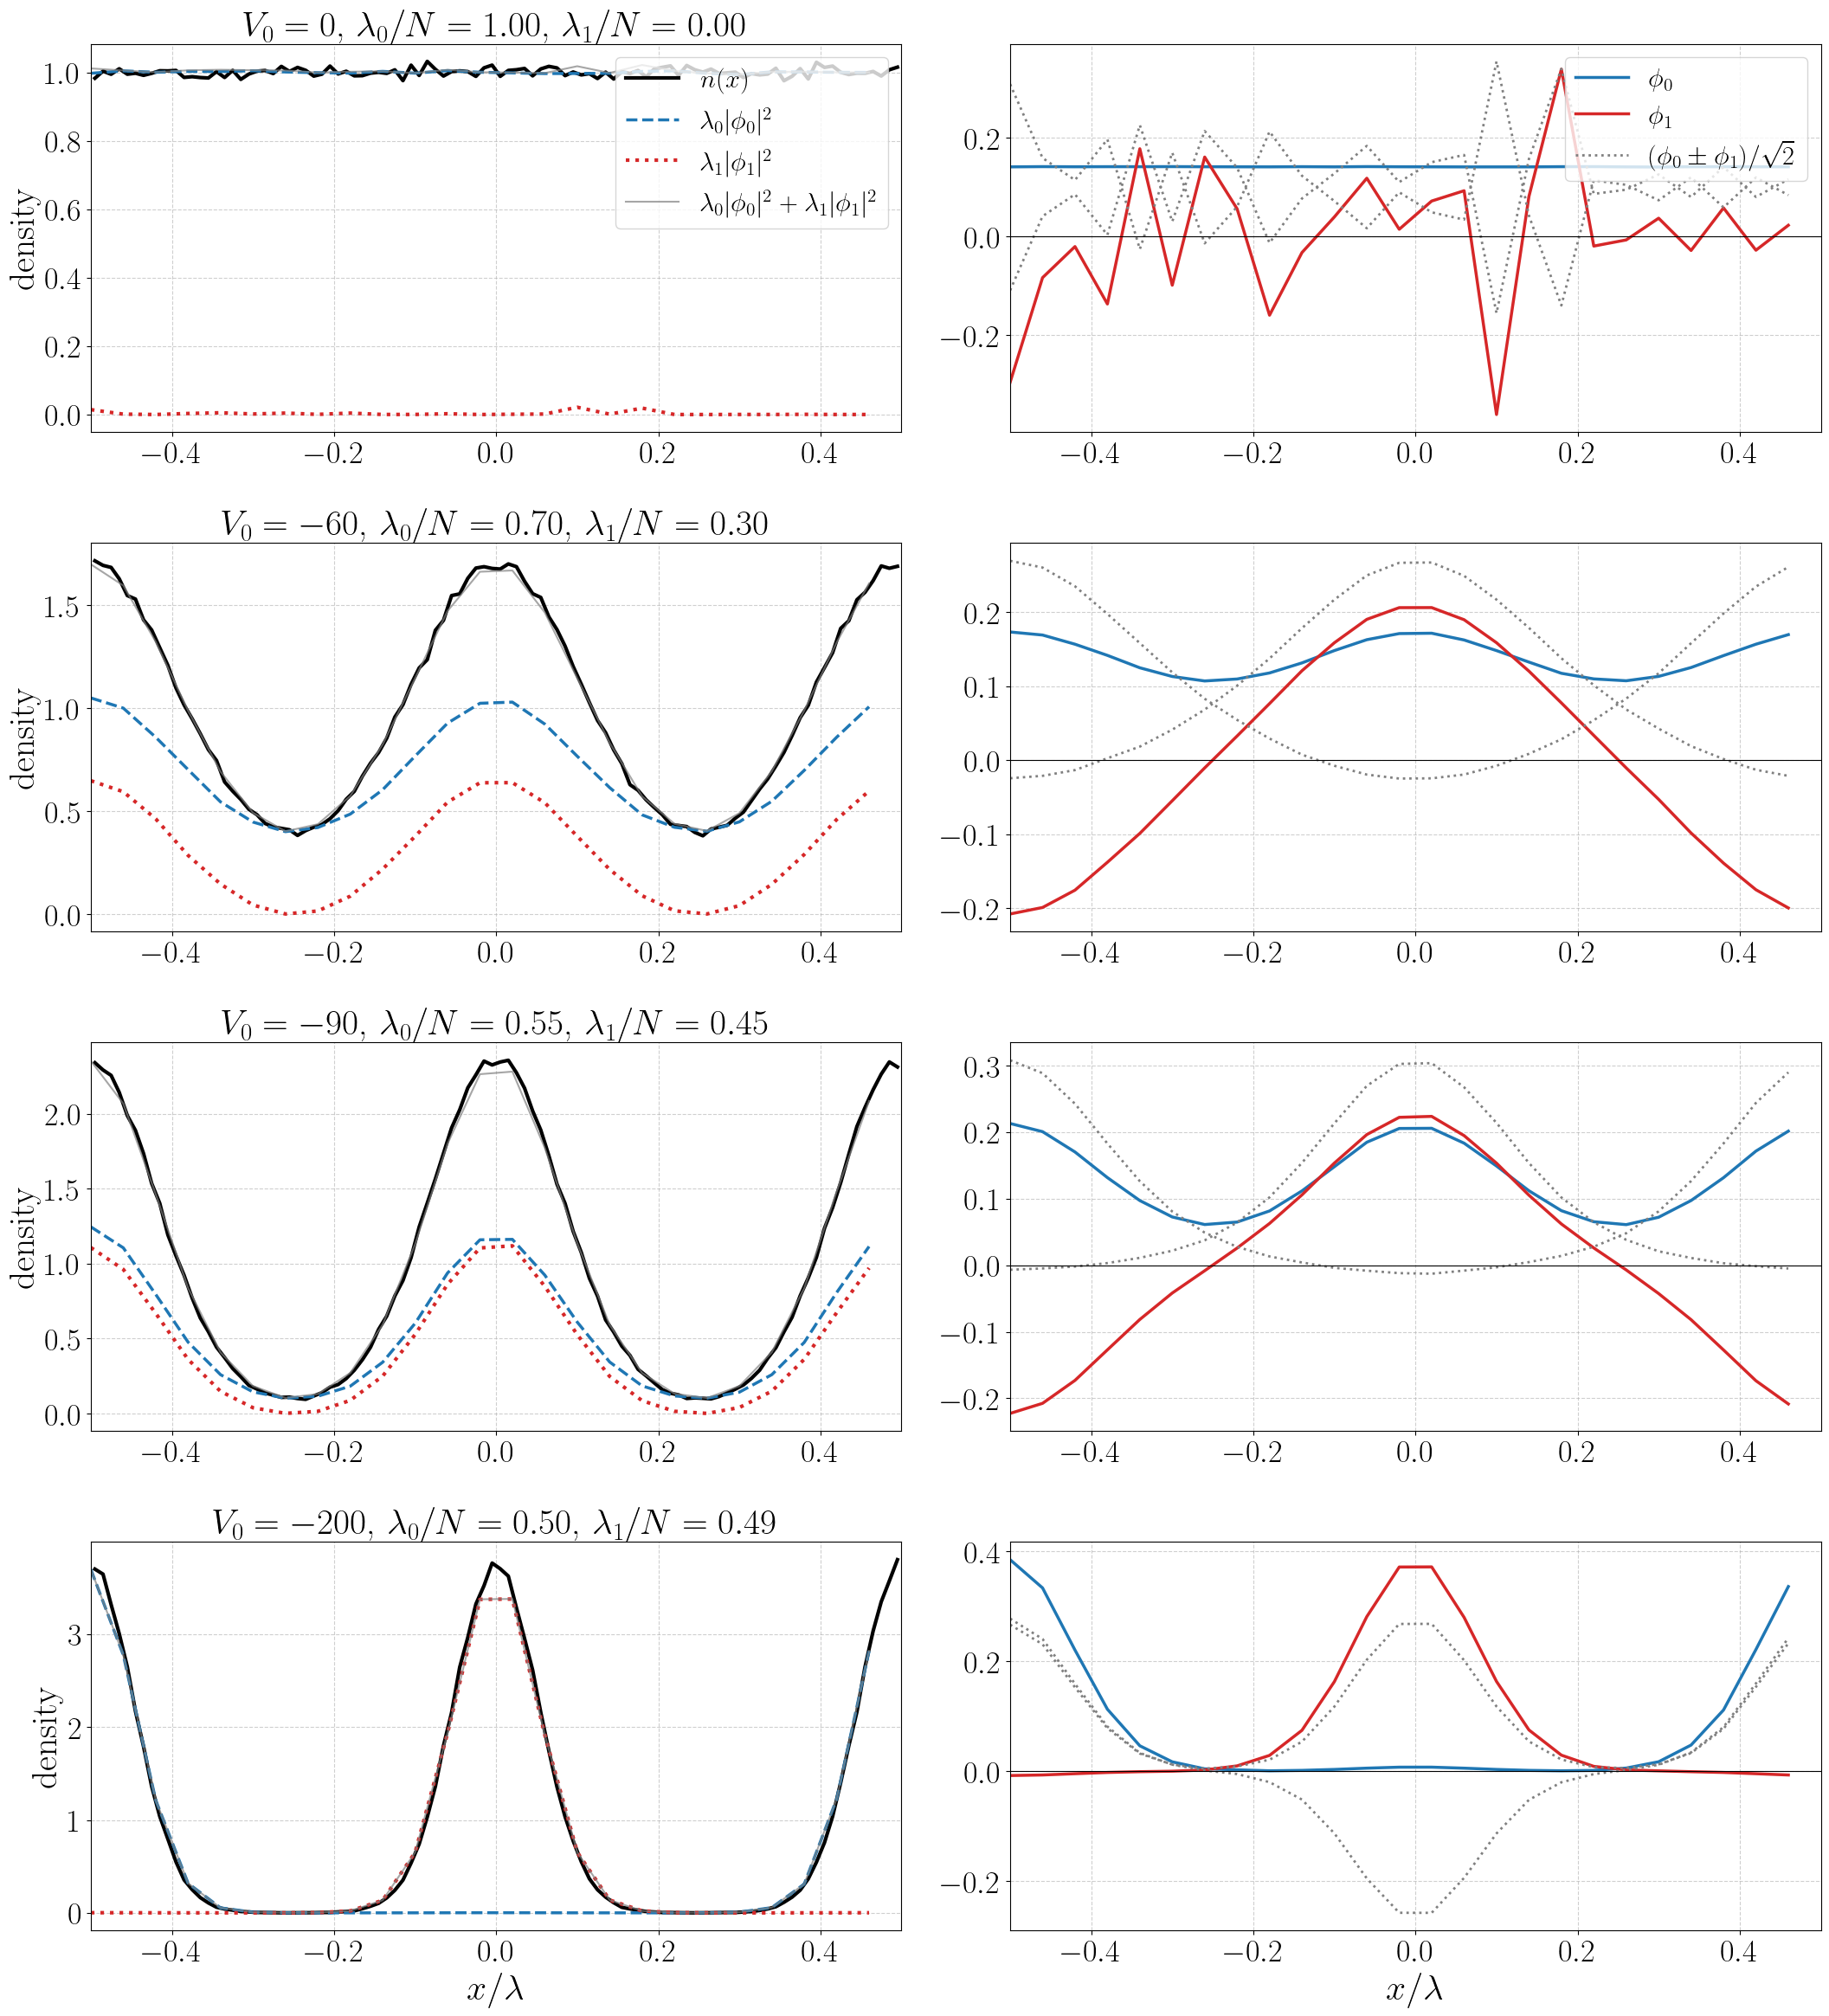

In [65]:
import numpy as np
import matplotlib.pyplot as plt
import os

plt.rcParams.update({
    "pgf.texsystem": "pdflatex",
    "font.family": "serif",
    "font.size": 30,
    "axes.titlesize": 30,
    "axes.labelsize": 30,
    "xtick.labelsize": 26,
    "ytick.labelsize": 26,
    "legend.fontsize": 22,
    "text.usetex": True,
    "pgf.rcfonts": False,
})

# ------------------- DATA LOCATION -------------------

base = r"C:\Users\marta\Downloads\Cavity_mediated_interaction_TFM_restructured(2)\numpy_arrays_VMC\constant_density_1.0"

density = 1.0
num_part = 50                                   # N to analyse
V0_kac_show = [0.0, -60.0, -90.0, -200.0]       # one row per value: uniform, crossover, deep


def get_L(N):
    return N / density


def load(kind, N, V0_kac):
    L = get_L(N)
    V0 = V0_kac / N + 0.0
    path = os.path.join(base, kind, f"V0={V0:.3f}", f"{kind}_{N}_{V0:.3f}_{L:.1f}.npy")
    if not os.path.isfile(path):
        raise FileNotFoundError(path)
    return np.load(path).astype(float)


def natural_orbitals(N, V0_kac):
    """Two leading natural orbitals of rho_1, folded onto one cavity period.

    Returns x (one period), lambda_0, lambda_1, phi_0(x), phi_1(x) on the full box, and the
    full-box grid. Orbitals are normalized to int |phi|^2 dx = 1 over the box.
    """
    L = get_L(N)
    rho1 = load("obdm", N, V0_kac)
    nb = rho1.shape[0]
    dx = L / nb

    n_cells = int(round(L))                     # average over lattice translations (exact symmetry)
    if nb % n_cells == 0:
        shift = nb // n_cells
        rho1 = sum(np.roll(rho1, (n * shift, n * shift), axis=(0, 1))
                   for n in range(n_cells)) / n_cells

    lam, vec = np.linalg.eigh(rho1 * dx)
    lam, vec = lam[::-1], vec[:, ::-1]
    phi = vec[:, :2] / np.sqrt(dx)

    x_box = -L / 2 + dx * (np.arange(nb) + 0.5)
    i0 = np.argmin(np.abs(x_box))               # fix the arbitrary sign: phi > 0 at x = 0
    for j in range(2):
        if phi[i0, j] < 0:
            phi[:, j] *= -1
    return x_box, lam[0], lam[1], phi[:, 0], phi[:, 1]


def fold(x_box, f):
    """Average a function on the full box over the cavity periods -> one period [-0.5, 0.5).

    The OBDM grid has an integer number of bins per period, so the box splits exactly
    into n_cells blocks that are averaged; positions are then mapped to [-0.5, 0.5).
    """
    L = len(x_box) * (x_box[1] - x_box[0])
    n_cells = int(round(L))
    nb_cell = len(x_box) // n_cells
    f_cell = f[: n_cells * nb_cell].reshape(n_cells, nb_cell).mean(axis=0)
    x_cell = (x_box[:nb_cell] + 0.5) % 1.0 - 0.5
    order = np.argsort(x_cell)
    return x_cell[order], f_cell[order]


# ------------------- FIGURE -------------------
# Left column : total density n(x) and condensate densities lambda_l |phi_l(x)|^2 (one period)
# Right column: the orbitals themselves (signed), on two periods so the sign pattern is visible

rows = []
for V0_kac in V0_kac_show:
    try:
        n_x = load("hist_1D", num_part, V0_kac)              # one period, unit integral
        x_box, lam0, lam1, phi0, phi1 = natural_orbitals(num_part, V0_kac)
        rows.append((V0_kac, n_x, x_box, lam0, lam1, phi0, phi1))
    except FileNotFoundError as e:
        print("missing:", e)

fig, axes = plt.subplots(len(rows), 2, figsize=(22, 6 * len(rows)), squeeze=False)

for r, (V0_kac, n_x, x_box, lam0, lam1, phi0, phi1) in enumerate(rows):
    ax_d, ax_o = axes[r]

    # --- densities on one period ---
    x_h = np.linspace(-0.5, 0.5, len(n_x), endpoint=False) + 0.5 / len(n_x)
    n_x = density * n_x / (np.sum(n_x) / len(n_x))            # n(x) with <n> = rho
    xc, d0 = fold(x_box, lam0 * phi0**2)
    _,  d1 = fold(x_box, lam1 * phi1**2)

    ax_d.plot(x_h, n_x, "-", color="black", linewidth=3, label=r"$n(x)$")
    ax_d.plot(xc, d0, "--", color="#1f77b4", linewidth=2.5, label=r"$\lambda_0|\phi_0|^2$")
    ax_d.plot(xc, d1, ":", color="#d62728", linewidth=3, label=r"$\lambda_1|\phi_1|^2$")
    ax_d.plot(xc, d0 + d1, "-", color="gray", linewidth=1.5, alpha=0.7,
              label=r"$\lambda_0|\phi_0|^2+\lambda_1|\phi_1|^2$")
    ax_d.set_xlim(-0.5, 0.5)
    ax_d.set_ylabel(r"density")
    ax_d.set_title(fr"$V_0={V0_kac:.0f}$, $\lambda_0/N={lam0/num_part:.2f}$, $\lambda_1/N={lam1/num_part:.2f}$")
    ax_d.grid(True, linestyle="--", alpha=0.6)
    if r == 0:
        ax_d.legend(loc="upper right")

    # --- orbitals on two periods around x = 0 ---
    mask = (x_box >= -0.5) & (x_box < 0.5)
    ax_o.plot(x_box[mask], phi0[mask], "-", color="#1f77b4", linewidth=2.5, label=r"$\phi_0$")
    ax_o.plot(x_box[mask], phi1[mask], "-", color="#d62728", linewidth=2.5, label=r"$\phi_1$")
    # In the degenerate case any rotation of (phi_0, phi_1) is a natural orbital;
    # (phi_0 +- phi_1)/sqrt(2) are the two localized "combs" of the Z2 branches.
    ax_o.plot(x_box[mask], (phi0[mask] + phi1[mask]) / np.sqrt(2), ":", color="gray", linewidth=2,
              label=r"$(\phi_0\pm\phi_1)/\sqrt{2}$")
    ax_o.plot(x_box[mask], (phi0[mask] - phi1[mask]) / np.sqrt(2), ":", color="gray", linewidth=2)
    ax_o.axhline(0, color="black", linewidth=0.8)
    ax_o.set_xlim(-0.5, 0.5)
    ax_o.grid(True, linestyle="--", alpha=0.6)
    if r == 0:
        ax_o.legend(loc="upper right")

axes[-1][0].set_xlabel(r"$x/\lambda$")
axes[-1][1].set_xlabel(r"$x/\lambda$")
plt.tight_layout()
os.makedirs("final_imag", exist_ok=True)
plt.savefig(f"final_imag/condensate_density_N{num_part}.pdf", dpi=600, bbox_inches="tight")
plt.show()

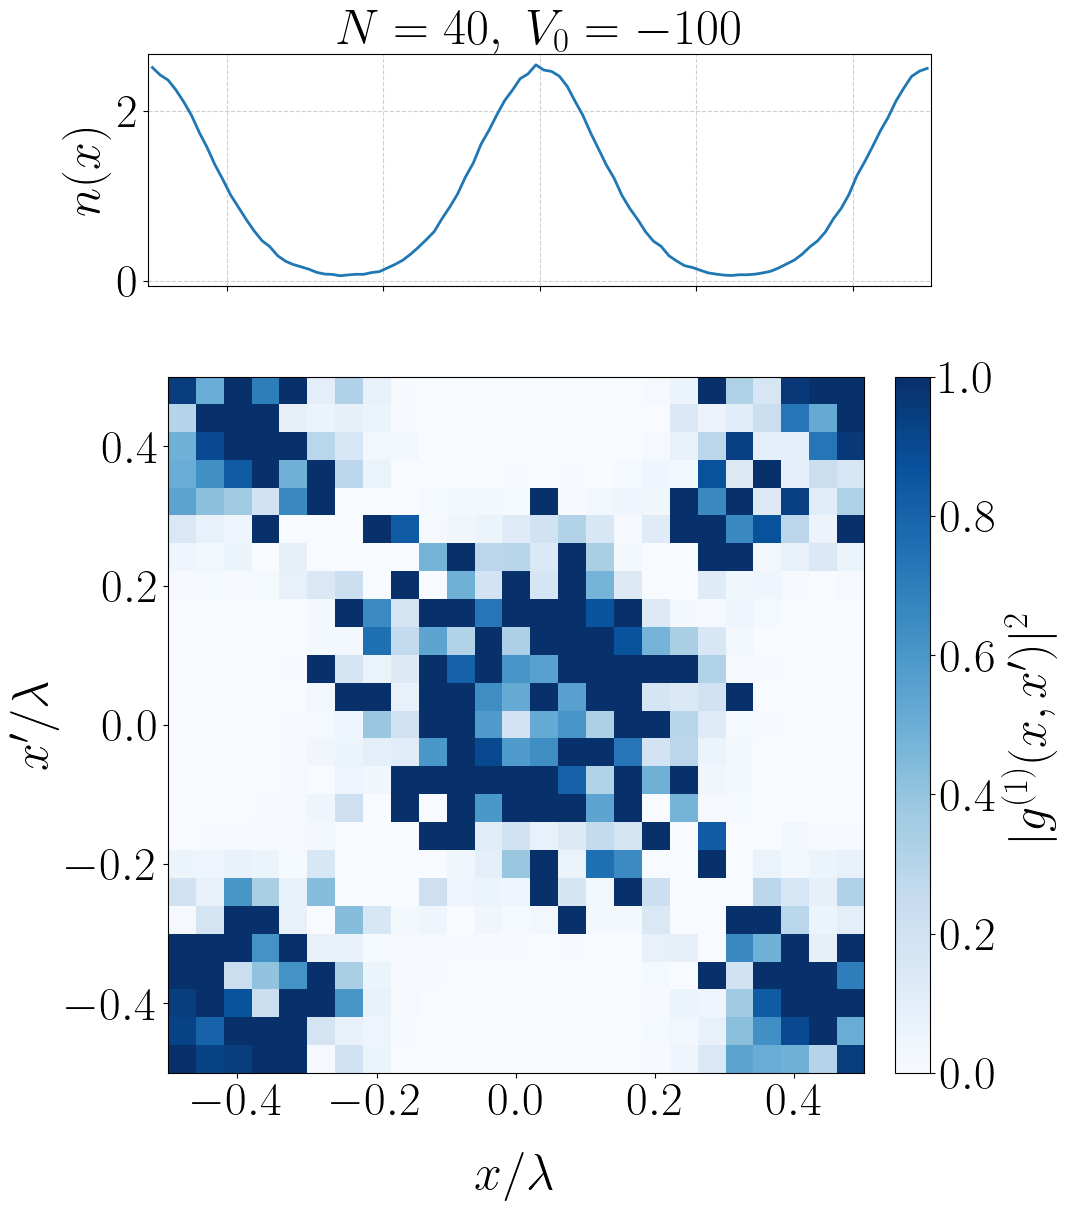

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import os

plt.rcParams.update({
    "pgf.texsystem": "pdflatex",
    "font.family": "serif",
    "font.size": 36,
    "axes.titlesize": 36,
    "axes.labelsize": 36,
    "xtick.labelsize": 34,
    "ytick.labelsize": 34,
    "legend.fontsize": 30,
    "figure.titlesize": 36,
    "text.usetex": True,
    "pgf.rcfonts": False,
})

# ------------------- DATA LOCATION -------------------

root = r"C:\Users\marta\Downloads\Cavity_mediated_interaction_TFM_restructured(2)"
base_vmc = os.path.join(root, "numpy_arrays_VMC", "constant_density_1.0")
base_dmc = os.path.join(root, "numpy_arrays_DMC", "constant_density_1.0")

# Which estimator to plot: "vmc", "dmc" or "extrapolated" (2 * DMC - VMC)
estimator = "vmc"

# DMC run parameters (part of the DMC file names)
n_walkers = 200
dtau = 0.0010
n_steps = 3000
dmc_suffix = "IS"                              # importance sampling

density = 1.0                                  # rho; L = N / density
Ns_list = list(range(10, 41, 5))
V0_kac_list = np.arange(0.0, -251.0, -10.0)    # Kac couplings V0_kac = N * V0 (bare)

# Extrapolation N -> infinity: linear fit in 1/N using the sizes N >= N_min_fit
N_min_fit = 20
fit_deg = 1

compute_zoom = True                            # hist_1D binned over one cavity period


def get_L(num_part):
    return num_part / density


def load_array(kind, num_part, V0_kac):
    """Load hist_1D, obdm or SSF for (N, V0_kac) with the chosen estimator.

    VMC folder : <kind>/V0=<V0>/<kind>_<N>_<V0>_<L>.npy
    DMC folder : <dir>/V0=<V0>/<pre>[_extrap]_<n_walkers>_<dtau>_<N>_<n_steps>_<V0>_<L>_<suffix>.npy
                 (hist_1D is stored as hist_1d/ with prefix hist1d; "_extrap" = 2*DMC - VMC
                 computed by the DMC run itself, "_vmc_" = the VMC of that same run).
    """
    L = get_L(num_part)
    V0 = V0_kac / num_part + 0.0               # bare V0 used in the simulation (+0.0 avoids "-0.000000")
    tail = f"{V0:.3f}_{L:.1f}"

    def _vmc_path():
        return os.path.join(base_vmc, kind, f"V0={V0:.3f}", f"{kind}_{num_part}_{tail}.npy")

    def _dmc_path(tag):                        # tag: "" (mixed estimator), "_extrap" or "_vmc"
        folder = "hist_1d" if kind == "hist_1D" else kind
        prefix = "hist1d" if kind == "hist_1D" else kind
        if tag == "_vmc":                      # VMC of the same DMC run (no DMC parameters in the name)
            name = f"{prefix}_vmc_{num_part}_{tail}.npy"
        else:
            name = f"{prefix}{tag}_{n_walkers}_{dtau:.4f}_{num_part}_{n_steps}_{tail}_{dmc_suffix}.npy"
        return os.path.join(base_dmc, folder, f"V0={V0:.3f}", name)

    def _load(path):
        if not os.path.isfile(path):
            raise FileNotFoundError(path)
        arr = np.load(path).real.astype(float)
        if kind == "hist_1D":                  # normalize n(x)
            interval = 1.0 if compute_zoom else L
            arr /= np.sum(arr) * interval / len(arr)
        return arr

    if estimator == "vmc":
        return _load(_vmc_path())
    if estimator == "dmc":
        return _load(_dmc_path(""))
    if estimator == "extrapolated":
        return _load(_dmc_path("_extrap"))
    raise ValueError(f"unknown estimator {estimator}")


def leggett_bound(num_part, V0_kac):
    """rho_S/rho upper bound (Leggett): 1 / (<n> <1/n>), averages over the binned interval."""
    L = get_L(num_part)
    n_x = load_array("hist_1D", num_part, V0_kac)
    interval = 1.0 if compute_zoom else L
    dx = interval / len(n_x)

    n_x /= np.sum(n_x * dx)
    n_x = np.maximum(n_x, 1e-8)

    mean_n = np.sum(n_x * dx) / interval
    mean_inv_n = np.sum(dx / n_x) / interval
    return 1.0 / (mean_n * mean_inv_n)


def obdm_eigenvalues(num_part, V0_kac):
    """OBDM eigenvalues / N (descending), translation-averaged over the lattice."""
    L = get_L(num_part)
    rho1 = load_array("obdm", num_part, V0_kac)
    nb = rho1.shape[0]
    dx = L / nb

    n_cells = int(round(L))
    if nb % n_cells == 0:
        shift = nb // n_cells
        rho1 = sum(np.roll(rho1, (n * shift, n * shift), axis=(0, 1))
                   for n in range(n_cells)) / n_cells

    lam = np.linalg.eigvalsh(rho1 * dx)[::-1]
    return lam / num_part


def S_kc(num_part, V0_kac):
    """S(k_c)/N^2 = order parameter squared (finite as N -> infinity; S(k_c) itself grows ~N^2).

    k_c = 2 pi is entry n = L (index L - 1) of the saved S(k).
    """
    i_c = int(round(get_L(num_part))) - 1
    return load_array("SSF", num_part, V0_kac)[i_c] / num_part**2


# ------------------- |g^(1)(x,x')|^2 MAP: pozo-pozo vs configuracion A/B -------------------
# g1(x,x')^2 = rho_1(x,x')^2 / [rho(x) rho(x')]. Comparacion con Lode & Bruder Fig. 4:
# si hay fragmentacion Z2 por simetria A/B (y no por aislamiento tipo Mott de cada pozo),
# se espera un tablero de ajedrez de periodo lambda/2: ~1 entre pozos separados por lambda
# (misma configuracion), ~0 entre pozos separados por lambda/2 (configuraciones distintas).

V0_map = -100.0
N_map = max(Ns_list)                   # usa el N mas grande disponible
n_periods = 1                         # ventana mostrada: n_periods * lambda (lambda = 1)
dens_floor = 0.01                      # oculta puntos con densidad < dens_floor * max(densidad)

rho1 = load_array("obdm", N_map, V0_map)
L = get_L(N_map)
nb_bins = rho1.shape[0]
dx = L / nb_bins
x_box = -L / 2 + dx * (np.arange(nb_bins) + 0.5)

# Density used in the denominator and for the mask: the smooth n(x) from hist_1D (periodic,
# resampled onto the OBDM grid). diag(rho1) has very few counts per bin (some bins are exactly
# 0), which produced spurious NaN rows/columns (white lines) in the map.
n_hist = load_array("hist_1D", N_map, V0_map)
interval = 1.0 if compute_zoom else L
x_hist = -interval / 2 + (interval / len(n_hist)) * (np.arange(len(n_hist)) + 0.5)
n_hist = n_hist / (np.sum(n_hist) * interval / len(n_hist))          # unit integral over `interval`
n_x = np.interp(x_box, x_hist, n_hist, period=interval).clip(1e-12)
n_x *= N_map / (np.sum(n_x) * dx)                                    # normalize to N particles
g1sq = rho1**2 / np.outer(n_x, n_x)

half = n_periods / 2.0
mask = (x_box >= -half) & (x_box < half)
dens_ok = n_x > dens_floor * n_x.max()
keep = np.outer(dens_ok, dens_ok)
G = np.where(keep, g1sq, np.nan)[np.ix_(mask, mask)]

fig, (ax0, ax) = plt.subplots(2, 1, figsize=(11, 13), height_ratios=[1, 3], sharex=True)

n_x_map = n_hist
dx_hist = interval / len(n_x_map)
# tile n(x), which is binned over one cavity period, across the displayed window
reps = int(np.ceil(n_periods / interval)) + 1
x_tiled = np.concatenate([x_hist + k * interval for k in range(-reps, reps + 1)])
n_tiled = np.tile(n_x_map, 2 * reps + 1)
sel = (x_tiled >= -half) & (x_tiled < half)
ax0.plot(x_tiled[sel], n_tiled[sel], "-", color="C0", linewidth=2)
ax0.set_ylabel(r"$n(x)$")
ax0.set_title(fr"$N={N_map},\ V_0={V0_map:.0f}$")
ax0.grid(True, linestyle="--", alpha=0.6)

im = ax.imshow(G, origin="lower", extent=[-half, half, -half, half], cmap="Blues", vmin=0, vmax=1,
               interpolation="nearest")
ax.set_xlabel(r"$x/\lambda$", labelpad=20)
ax.set_ylabel(r"$x'/\lambda$")
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label(r"$|g^{(1)}(x,x')|^2$")
plt.tight_layout()
os.makedirs("final_imag", exist_ok=True)
plt.savefig(f"final_imag/g1sq_map_N{N_map}_V0{V0_map:.0f}_{estimator}.pdf", dpi=600, bbox_inches="tight")

plt.show()